# When Does Copying Stop Paying Off? Environmental Harshness, Least Effort, and the Critical Threshold of Cumulative Culture

**Course**: Cultural Evolution (2025–2026)  
**Instructor**: Prof. Alexey Koshevoy (PR[AI]RIE Fellow & Postdoctoral Researcher, ENS-PSL)  
**Institution**: Master's in AI & Society (PSAI), PSL University / École Normale Supérieure  
**Author**: Rares Olteanu  

---

## Executive Summary & Project Architecture

In cultural evolution, social learning is frequently framed as an effortless adaptive shortcut, yet **Rogers' Paradox (1988)** demonstrates a fundamental trap: when copying is cheap, imitators proliferate at the expense of individual innovators until cultural knowledge stagnates and population mean fitness drops back to that of solitary learners. Meanwhile, as **Henrich (2004)** formalized for technological evolution, imperfect imitation naturally degrades complex skills unless actively replenished by innovation.

Following **Professor Alexey Koshevoy's** supervisory guidance (*"Start with the simplest thing first, reflect deeply on theory, think about a general case, and add complex extensions at the end"*), this notebook is structured into two clear parts:

* **Part I — The Core Minimal Model & General Case Analysis**:
  1. **The Parsimonious Question**: *In a cultural species where copying others is cheap but imperfect, and inventing new solutions is costly, how much copying can a society sustain before an environmental scarcity shock triggers cultural collapse?*
  2. **Real-World Economic Translation (Patents & Corporate R&D)**: Mapping cultural skill $z_i(t)$ to **corporate patent portfolio quality**, copying to **open standards / fast-follower licensing** ($C_{\text{copy}} = 1.0$), and individual innovation to **in-house frontier R&D** ($C_{\text{innov}} = 5.0$).
  3. **The Principle of Least Effort as a Transmission Bias**: Operationalized through an energetic cost disparity ($C_{\text{copy}} = 1.0 < C_{\text{innov}} = 5.0$) coupled with **Henrich's (2004) Gumbel skill-loss dynamics** ($\alpha_{\text{loss}} = 0.8$).
  4. **The Copier Proportion Sweep ($0\% \to 100\%$)**: Testing fixed mixtures across 50 Monte Carlo runs per step reveals an exact critical tipping point ($p^* \approx 70\%$) separating resilient division of labor from austerity collapse ($\Pi < 0$).
  5. **The General Case (2D Phase Diagrams)**: Sweeping both environmental harshness ($H \in [2, 14]$) and imitation error ($\alpha_{\text{loss}} \in [0.2, 1.2]$) reveals the continuous phase boundary governing technological survival.
  6. **Theoretical Reflection**: Engaging directly with Henrich (2004), Charbonneau (2015, 2018), Rogers (1988), and corporate R&D portfolio strategy.

* **Part II — Advanced Extensions ("Extras")**:
  * **Extension 1 (Dynamic Self-Organization)**: Adaptive Social Brain (Rescorla-Wagner $\Delta$-rule) & 5-Strategy benchmark trajectories.
  * **Extension 2 (Endogenous Co-Evolution)**: Discrete Replicator Dynamics converging to an asymmetric Evolutionarily Stable State (ESS).
  * **Extension 3 (Interactive Sandbox)**: Live 60-FPS HTML5/Canvas parameter playground.
  * **Extension 4 (Professor's Rank-Frequency Model)**: Yule-Simon process contrasting neutral drift, frequency independence, prestige, and conformist bias.
  * **Extension 5 (Technological Recombination)**: Modular patent citation network generating heavy-tailed power laws (Charbonneau framework).
  * **Extension 6 (Corporate R&D Time Machine)**: Macro-technological scenario simulator stress-testing an ensemble of **1,000 competing corporate firms** over 100 quarterly epochs across macroeconomic shocks.
  * **Extension 7 (Empirical Benchmark)**: Trial-by-trial validation on $N = 2{,}544$ aligned human choices from Najar et al. (2020, *PLoS Biology*).


---
# Part I: Core Model & General Theory

## Section 1: Research Question & Theoretical Motivation

### 1.1 The Core Question in Plain Terms

> **Core Research Question**:  
> *In a cultural species where copying others is cheap but imperfect, and inventing new solutions is costly, how much social copying can a population tolerate before an environmental scarcity shock triggers cultural collapse?*

This question directly addresses the central tension in **Rogers' Paradox (1988)** and **Henrich's (2004) treadmill model** under changing environmental pressure:
1. If copying is cheap, agents naturally gravitate toward it (**Principle of Least Effort as a transmission bias**).
2. However, copying does not generate novel adaptive information; it only redistributes existing skills, which decay on average due to imperfect replication (**Henrich’s Gumbel skill loss**).
3. In easy, forgiving environments, relying heavily on copying looks like an optimal energy-saving strategy (the **"Free-Rider Illusion"**).
4. When environmental austerity strikes (higher living/metabolic demands $H$), at what exact proportion of copiers ($p^*$) does cumulative culture fail to generate enough value to pay survival costs?

### 1.2 Real-World Application: Corporate R&D, Patents & Technological Obsolescence
As highlighted in discussion with **Professor Alexey Koshevoy**, this exact dynamical tension governs **corporate industrial policy and patent strategy**:
* **Frontier In-House R&D** ($C_{\text{innov}} = 5.0$): High burn rate, risky discovery increments ($\Delta z \sim \text{Exp}$), but generates novel intellectual property and patent breakthroughs.
* **Fast-Follower Copying & Licensing** ($C_{\text{copy}} = 1.0$): Cheap adoption of open standards and competitor patents, highly efficient in low-interest boom times, but produces no foundational patents.
* **Technological Obsolescence** ($\alpha_{\text{loss}} = 0.8$): Copied technology depreciates over time unless actively refreshed by in-house engineering competence.
* **Macroeconomic Austerity Crisis** ($H = 2.0 \to 10.0$): When market competition tightens or regulatory/borrowing costs surge, firms relying on $>70\%$ imitation experience technological insolvency ($\Pi < 0$).

### 1.3 Why Start with a Minimal Model of Technological Evolution?
As noted by **Charbonneau (2015, 2018)**, formal mathematical and agent-based modeling of **technological evolution** remains surprisingly sparse—aside from **Henrich's (2004)** classic skill-loss model, few simple, general models quantify how individual learning costs and imitation error interact under ecological pressure. Starting with fixed population mixtures ($p \in \{0\%, 10\%, \dots, 100\%\}$ copiers) eliminates unnecessary cognitive assumptions, allowing clean causal isolation of the phase boundary across general parameter regimes.


---
## Section 2: Specification of the Simplest Model

The baseline model tracks a population of $N = 100$ agents over $T = 100$ discrete generations using three simple rules:

### 2.1 Individual Net Payoff ($\Pi_i$) & Real-World Translation
Following standard cultural evolution ABM conventions (Mesoudi, 2011; Acerbi, Mesoudi, & Smolla, 2022), every agent $i$ with technological competence $z_i(t) \ge 0$ receives:
$$\Pi_i(t) = \underbrace{z_i(t)}_{\text{Cultural Skill}} - \underbrace{H(t)}_{\text{Environmental Harshness}} - \underbrace{C(a_i(t))}_{\text{Effort Cost}}$$

| Cultural Evolution Variable | Anthropological Meaning | Corporate Economics / Patent Equivalent |
| :--- | :--- | :--- |
| **$z_i(t)$** | Individual cultural skill / technological competence | **Patent Portfolio Quality & Technological Capital** |
| **$C(\text{INNOV}) = 5.0$** | High cognitive effort to discover new techniques | **In-House Frontier R&D Capital Investment** (high burn rate) |
| **$C(\text{COPY}) = 1.0$** | Low energetic effort to imitate a peer demonstrator | **Reverse-Engineering & Patent Licensing** (low-cost rollout) |
| **$\alpha_{\text{loss}} = 0.8$** | Henrich Gumbel transmission loss (skill degradation) | **Technological Depreciation & Knowledge Obsolescence** |
| **$H(t) = 2.0 \to 10.0$** | Baseline metabolic survival / environmental living cost | **Macroeconomic Austerity & Cost of Capital Shock** |
| **$\Pi_i(t) = z - H - C$** | Net biological fitness / reproductive success | **Corporate Operating Margin & Net Cashflow** ($\Pi < 0 \implies \text{insolvency}$) |

* **Environmental Harshness ($H(t)$)**:
  $$H(t) = \begin{cases} H_{\text{low}} = 2.0, & t < 40 \quad (\text{Benign Boom Era}) \\ H_{\text{high}} = 10.0, & t \ge 40 \quad (\text{Austerity / Scarcity Shock}) \end{cases}$$
* **Effort Cost ($C$) — The Principle of Least Effort**:
  $$C(\text{COPY}) = 1.0, \qquad C(\text{INNOVATE}) = 5.0$$
  Copying requires 5 times less effort than innovating, acting as an intrinsic energetic transmission bias.

### 2.2 Cultural Transmission & Discovery Dynamics
* **When an agent Innovates ($a_i = 1$)**: They pay cost $C_{\text{innov}} = 5.0$ to explore new solutions, improving their skill by an exponential discovery increment:
  $$z_i(t+1) = z_i(t) + \Delta z_i, \quad \Delta z_i \sim \text{Exponential}(\text{scale} = \lambda_{\text{innov}} = 1.5)$$
* **When an agent Copies ($a_i = 0$)**: They pay cost $C_{\text{copy}} = 1.0$, select a demonstrator $j$ from the previous generation weighted by skill/prestige ($\alpha = 4.0$):
  $$\mathbb{P}(\text{select } j) = \frac{(z_j(t) - \min z + \epsilon)^\alpha}{\sum_{m=1}^N (z_m(t) - \min z + \epsilon)^\alpha}$$
  and reproduce the demonstrator's skill subject to **Henrich's (2004) asymmetric Gumbel transmission noise**:
  $$z_i(t+1) = \max\left(0, \; z_j(t) + \epsilon_i\right), \quad \epsilon_i \sim \text{Gumbel}(\mu = -\alpha_{\text{loss}}, \; \beta_{\text{disp}})$$
  with baseline transmission loss $\alpha_{\text{loss}} = 0.8$ and dispersion $\beta_{\text{disp}} = 0.3$.

### 2.3 The Experiment: Fixed Copier Proportion Sweep ($0\%$ to $100\%$)
In each population mixture, a fixed share $p \in \{0\%, 10\%, 20\%, \dots, 90\%, 100\%\}$ of agents act as copiers while the remaining $1 - p$ act as innovators. We evaluate both the baseline case ($H_{\text{high}}=10.0, \alpha_{\text{loss}}=0.8$) and the **general case** across sweeping shock severities and imitation error rates.


### Code Block 1: Reproducible Environment Setup & Plot Styling
> [!NOTE]
> Initializes NumPy (`default_rng`), Pandas, SciPy, and publication plotting aesthetics (`ticks` theme with colorblind-safe palette). Logs runtime library versions for computational reproducibility (I4R standard).


In [1]:
# Code Block 1: Scientific Environment Setup and Plot Styling
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks", palette="colorblind", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version:  {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
print("Computational Reproducibility Environment Verified.")


Python Version: 3.13.5
NumPy Version:  2.3.4
Pandas Version: 2.3.3
Computational Reproducibility Environment Verified.


### Code Block 2: Core Simulation Engine (`HarshnessCulturalArena`)
> [!NOTE]
> Vectorized agent-based simulation engine implementing the core minimal model (`run_fixed_mixture_sweep`, `run_general_case_phase_diagram`) as well as the secondary extensions (`run_ensemble`, `run_replicator_dynamics`) used in Part II.


In [2]:
# Code Block 2: Vectorized Cultural Evolution Simulation Engine
class HarshnessCulturalArena:
    # Vectorized agent-based simulation modeling cumulative cultural evolution
    # under environmental harshness shocks, cognitive learning costs, and transmission noise.
    def __init__(
        self,
        N=100,
        generations=100,
        shock_gen=40,
        H_low=2.0,
        H_high=10.0,
        cost_copy=1.0,
        cost_innov=5.0,
        alpha_prestige=4.0,
        gumbel_loss=0.8,
        gumbel_beta=0.3,
        innov_lambda=1.5,
        eta=0.35,
        tau=1.0,
        seed=101101
    ):
        self.N = N
        self.T = generations
        self.T_shock = shock_gen
        self.H_low = H_low
        self.H_high = H_high
        self.cost_copy = cost_copy
        self.cost_innov = cost_innov
        self.alpha_prestige = alpha_prestige
        self.gumbel_loss = gumbel_loss
        self.gumbel_beta = gumbel_beta
        self.innov_lambda = innov_lambda
        self.eta = eta
        self.tau = tau
        self.seed = seed

    def simulate_single_run(self, strategy_mode, rng, fixed_innov_prob=None):
        N = self.N
        z = rng.uniform(6.0, 7.0, size=N)

        if strategy_mode == 2:
            q_vals = np.zeros((N, 2))
            q_vals[:, 0] = 3.5
            q_vals[:, 1] = 0.0
        elif strategy_mode == 4:
            n_copier = int(0.80 * N)
            n_innov = int(0.10 * N)
            n_adapt = N - (n_copier + n_innov)
            q_vals = np.zeros((n_adapt, 2))
            q_vals[:, 0] = 3.5
            q_vals[:, 1] = 0.0
        else:
            q_vals = None

        history = {
            "mean_payoff": np.zeros(self.T),
            "mean_skill": np.zeros(self.T),
            "diversity": np.zeros(self.T),
            "pct_innovating": np.zeros(self.T),
        }

        for t in range(self.T):
            H = self.H_high if t >= self.T_shock else self.H_low
            actions = np.zeros(N, dtype=int)

            if strategy_mode == 0:
                actions[:] = 0
            elif strategy_mode == 1:
                actions[:] = 1
            elif strategy_mode == 2:
                v_copy = q_vals[:, 0] / self.tau
                v_innov = q_vals[:, 1] / self.tau
                max_v = np.maximum(v_copy, v_innov)
                exp_c = np.exp(v_copy - max_v)
                exp_i = np.exp(v_innov - max_v)
                p_innov = exp_i / (exp_c + exp_i)
                actions = (rng.random(size=N) < p_innov).astype(int)
            elif strategy_mode == 3:
                p_inv = fixed_innov_prob if fixed_innov_prob is not None else 0.05
                actions = (rng.random(size=N) < p_inv).astype(int)
            elif strategy_mode == 4:
                n_copier = int(0.80 * N)
                n_innov = int(0.10 * N)
                n_adapt = N - (n_copier + n_innov)
                actions[:n_copier] = 0
                actions[n_copier : n_copier + n_innov] = 1
                if n_adapt > 0:
                    v_copy = q_vals[:, 0] / self.tau
                    v_innov = q_vals[:, 1] / self.tau
                    max_v = np.maximum(v_copy, v_innov)
                    exp_c = np.exp(v_copy - max_v)
                    exp_i = np.exp(v_innov - max_v)
                    p_innov = exp_i / (exp_c + exp_i)
                    actions[n_copier + n_innov:] = (rng.random(size=n_adapt) < p_innov).astype(int)

            z_next = np.copy(z)
            costs = np.zeros(N)

            copy_idx = np.where(actions == 0)[0]
            if len(copy_idx) > 0:
                costs[copy_idx] = self.cost_copy
                z_shifted = z - np.min(z) + 1e-4
                weights = z_shifted ** self.alpha_prestige
                denom = np.sum(weights)
                probs = weights / denom if denom > 0 else np.ones(N) / N
                models = rng.choice(N, size=len(copy_idx), p=probs, replace=True)
                gumbel_noise = rng.gumbel(loc=-self.gumbel_loss, scale=self.gumbel_beta, size=len(copy_idx))
                z_next[copy_idx] = np.maximum(0.0, z[models] + gumbel_noise)

            innov_idx = np.where(actions == 1)[0]
            if len(innov_idx) > 0:
                costs[innov_idx] = self.cost_innov
                dz = rng.exponential(scale=self.innov_lambda, size=len(innov_idx))
                z_next[innov_idx] = z[innov_idx] + dz

            payoffs = z_next - H - costs

            if strategy_mode == 2:
                for act in [0, 1]:
                    idx = np.where(actions == act)[0]
                    if len(idx) > 0:
                        rpe = payoffs[idx] - q_vals[idx, act]
                        q_vals[idx, act] += self.eta * rpe
            elif strategy_mode == 4:
                n_copier = int(0.80 * N)
                n_innov = int(0.10 * N)
                adapt_start = n_copier + n_innov
                if adapt_start < N:
                    for act in [0, 1]:
                        sub_idx = np.where(actions[adapt_start:] == act)[0]
                        if len(sub_idx) > 0:
                            global_idx = sub_idx + adapt_start
                            rpe = payoffs[global_idx] - q_vals[sub_idx, act]
                            q_vals[sub_idx, act] += self.eta * rpe

            z = z_next
            history["mean_payoff"][t] = np.mean(payoffs)
            history["mean_skill"][t] = np.mean(z)
            history["diversity"][t] = np.std(z)
            history["pct_innovating"][t] = np.mean(actions == 1)

        return history

    def run_fixed_mixture_sweep(self, sweep_grid=None, n_runs=50):
        # Sweeps Copier Proportion: 0%, 10%, 20%, ..., 90%, 100%
        if sweep_grid is None:
            sweep_grid = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]

        master_rng = np.random.default_rng(self.seed + 777)
        run_seeds = master_rng.integers(100000, 999999, size=n_runs)

        records = []
        for p_copier in sweep_grid:
            p_innov = 1.0 - p_copier
            cums, pre_payoffs, post_payoffs, final_skills = [], [], [], []
            for r_seed in run_seeds:
                r_rng = np.random.default_rng(r_seed)
                hist = self.simulate_single_run(3, r_rng, fixed_innov_prob=p_innov)
                cums.append(np.sum(hist["mean_payoff"]))
                pre_payoffs.append(hist["mean_payoff"][self.T_shock - 1])
                post_payoffs.append(hist["mean_payoff"][-1])
                final_skills.append(hist["mean_skill"][-1])

            mean_post = float(np.mean(post_payoffs))
            status = "Resilient (Payoff > 0)" if mean_post > 0 else "Collapsed (Payoff < 0)"

            records.append({
                "Copier_Proportion": f"{int(round(p_copier * 100))}%",
                "Innovator_Proportion": f"{int(round(p_innov * 100))}%",
                "Pre_Shock_Payoff": float(np.mean(pre_payoffs)),
                "Post_Shock_Payoff": mean_post,
                "Cumulative_Payoff": float(np.mean(cums)),
                "Std_Cumulative_Payoff": float(np.std(cums, ddof=1)),
                "Final_Skill": float(np.mean(final_skills)),
                "Survival_Status": status,
            })

        return pd.DataFrame(records)

    def run_general_case_phase_diagram(
        self,
        copier_grid=None,
        harshness_grid=None,
        loss_grid=None,
        n_runs=20,
    ):
        # Computes 2D general phase boundaries across Harshness and Gumbel Skill Loss
        if copier_grid is None:
            copier_grid = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
        if harshness_grid is None:
            harshness_grid = [2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0]
        if loss_grid is None:
            loss_grid = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]

        master_rng = np.random.default_rng(self.seed + 888)
        run_seeds = master_rng.integers(100000, 999999, size=n_runs)

        orig_H_high = self.H_high
        orig_loss = self.gumbel_loss

        mat_harshness = np.zeros((len(harshness_grid), len(copier_grid)))
        for i, h_val in enumerate(harshness_grid):
            self.H_high = h_val
            for j, p_copier in enumerate(copier_grid):
                p_innov = 1.0 - p_copier
                posts = []
                for r_seed in run_seeds:
                    r_rng = np.random.default_rng(r_seed)
                    hist = self.simulate_single_run(3, r_rng, fixed_innov_prob=p_innov)
                    posts.append(hist["mean_payoff"][-1])
                mat_harshness[i, j] = float(np.mean(posts))
        self.H_high = orig_H_high

        mat_loss = np.zeros((len(loss_grid), len(copier_grid)))
        for i, l_val in enumerate(loss_grid):
            self.gumbel_loss = l_val
            for j, p_copier in enumerate(copier_grid):
                p_innov = 1.0 - p_copier
                posts = []
                for r_seed in run_seeds:
                    r_rng = np.random.default_rng(r_seed)
                    hist = self.simulate_single_run(3, r_rng, fixed_innov_prob=p_innov)
                    posts.append(hist["mean_payoff"][-1])
                mat_loss[i, j] = float(np.mean(posts))
        self.gumbel_loss = orig_loss

        return {
            "copier_grid": copier_grid,
            "harshness_grid": harshness_grid,
            "loss_grid": loss_grid,
            "payoff_vs_harshness": mat_harshness,
            "payoff_vs_loss": mat_loss,
        }

    def run_ensemble(self, n_runs=50):
        strategies = {
            "Pure Copiers": 0,
            "Pure Innovators": 1,
            "Homogeneous Adaptive": 2,
            "Static 5% Mixture": 3,
            "Heterogeneous (80/10/10)": 4,
        }
        master_rng = np.random.default_rng(self.seed)
        run_seeds = master_rng.integers(100000, 999999, size=n_runs)
        results = {}
        for s_label, s_mode in strategies.items():
            trajectories = {"mean_payoff": [], "mean_skill": [], "diversity": [], "pct_innovating": []}
            for r_seed in run_seeds:
                r_rng = np.random.default_rng(r_seed)
                hist = self.simulate_single_run(s_mode, r_rng)
                for k in trajectories:
                    trajectories[k].append(hist[k])
            stat_dict = {}
            for k, arr_list in trajectories.items():
                arr = np.array(arr_list)
                stat_dict[k] = {
                    "mean": np.mean(arr, axis=0),
                    "lower": np.percentile(arr, 2.5, axis=0),
                    "upper": np.percentile(arr, 97.5, axis=0),
                }
            cums = np.sum(np.array(trajectories["mean_payoff"]), axis=1)
            stat_dict["cumulative_payoff"] = {
                "mean": float(np.mean(cums)),
                "lower": float(np.percentile(cums, 2.5)),
                "upper": float(np.percentile(cums, 97.5)),
            }
            results[s_label] = stat_dict
        return results

    def run_replicator_dynamics(self, n_runs=50, init_props=None, mu=0.03, seed=None):
        if init_props is None:
            init_props = [1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0]
        use_seed = seed if seed is not None else self.seed + 999
        master_rng = np.random.default_rng(use_seed)
        run_seeds = master_rng.integers(100000, 999999, size=n_runs)

        props_history = np.zeros((n_runs, self.T, 3))
        payoff_history = np.zeros((n_runs, self.T))
        skill_history = np.zeros((n_runs, self.T))

        for r, r_seed in enumerate(run_seeds):
            rng = np.random.default_rng(r_seed)
            props = np.array(init_props, dtype=float)
            z = rng.uniform(6.0, 7.0, size=self.N)
            q_vals = np.zeros((self.N, 2))
            q_vals[:, 0] = 3.5
            q_vals[:, 1] = 0.0

            for t in range(self.T):
                props_history[r, t] = props
                H = self.H_high if t >= self.T_shock else self.H_low
                counts = np.round(props * self.N).astype(int)
                counts[2] = self.N - (counts[0] + counts[1])
                c0, c1, c2 = counts[0], counts[1], counts[2]

                actions = np.zeros(self.N, dtype=int)
                if c1 > 0:
                    actions[c0 : c0 + c1] = 1
                if c2 > 0:
                    ad_slice = slice(c0 + c1, self.N)
                    v_copy = q_vals[ad_slice, 0] / self.tau
                    v_innov = q_vals[ad_slice, 1] / self.tau
                    max_v = np.maximum(v_copy, v_innov)
                    exp_c = np.exp(v_copy - max_v)
                    exp_i = np.exp(v_innov - max_v)
                    p_innov = exp_i / (exp_c + exp_i)
                    actions[ad_slice] = (rng.random(size=c2) < p_innov).astype(int)

                z_next = np.copy(z)
                costs = np.zeros(self.N)

                copy_idx = np.where(actions == 0)[0]
                if len(copy_idx) > 0:
                    costs[copy_idx] = self.cost_copy
                    z_shifted = z - np.min(z) + 1e-4
                    weights = z_shifted ** self.alpha_prestige
                    denom = np.sum(weights)
                    probs = weights / denom if denom > 0 else np.ones(self.N) / self.N
                    models = rng.choice(self.N, size=len(copy_idx), p=probs, replace=True)
                    gumbel_noise = rng.gumbel(loc=-self.gumbel_loss, scale=self.gumbel_beta, size=len(copy_idx))
                    z_next[copy_idx] = np.maximum(0.0, z[models] + gumbel_noise)

                innov_idx = np.where(actions == 1)[0]
                if len(innov_idx) > 0:
                    costs[innov_idx] = self.cost_innov
                    dz = rng.exponential(scale=self.innov_lambda, size=len(innov_idx))
                    z_next[innov_idx] = z[innov_idx] + dz

                payoffs = z_next - H - costs

                if c2 > 0:
                    ad_slice = slice(c0 + c1, self.N)
                    for act in [0, 1]:
                        sub = actions[ad_slice] == act
                        if np.any(sub):
                            g_idx = np.where(actions[ad_slice] == act)[0] + (c0 + c1)
                            rpe = payoffs[g_idx] - q_vals[g_idx, act]
                            q_vals[g_idx, act] += self.eta * rpe

                z = z_next
                p0 = np.mean(payoffs[:c0]) if c0 > 0 else 0.0
                p1 = np.mean(payoffs[c0 : c0 + c1]) if c1 > 0 else 0.0
                p2 = np.mean(payoffs[c0 + c1:]) if c2 > 0 else 0.0

                gps = np.array([p0, p1, p2])
                fit = gps - np.min(gps) + 1.0
                rep = props * (fit / np.sum(props * fit))
                rep = (1.0 - mu) * rep + mu * (1.0 / 3.0)
                rep = rep / np.sum(rep)

                counts = rng.multinomial(self.N, rep)
                props = counts / self.N

                payoff_history[r, t] = np.mean(payoffs)
                skill_history[r, t] = np.mean(z)

        return {
            "props_history": props_history,
            "payoff_history": payoff_history,
            "skill_history": skill_history,
        }

    def run_corporate_time_machine(self, num_firms=1000, generations=100, shock_gen=40, scenarios=None, seed_offset=777):
        if scenarios is None:
            scenarios = {
                "Fast-Follower Swarm (90% Copy / 10% R&D)": {
                    "copier_ratio": 0.90, "H_pre": 2.0, "H_post": 10.0, "color": "#d62728"
                },
                "Optimal Division of Labor (70% Copy / 30% R&D)": {
                    "copier_ratio": 0.70, "H_pre": 2.0, "H_post": 10.0, "color": "#2ca02c"
                },
                "Balanced Tech Firm (50% Copy / 50% R&D)": {
                    "copier_ratio": 0.50, "H_pre": 2.0, "H_post": 10.0, "color": "#1f77b4"
                },
                "DeepTech Pioneer (10% Copy / 90% R&D)": {
                    "copier_ratio": 0.10, "H_pre": 2.0, "H_post": 10.0, "color": "#9467bd"
                },
            }

        results = {}
        master_rng = np.random.default_rng(self.seed + seed_offset)

        for s_idx, (scen_name, params) in enumerate(scenarios.items()):
            p_copy = params.get("copier_ratio", 0.70)
            h_pre = params.get("H_pre", self.H_low)
            h_post = params.get("H_post", self.H_high)
            color = params.get("color", "#333333")

            rng = np.random.default_rng(master_rng.integers(100000, 999999))
            z = np.full(num_firms, 2.0)
            operating_margin = np.zeros((num_firms, generations))
            valuation_history = np.zeros((num_firms, generations))
            cumulative_profit = np.zeros((num_firms, generations))
            survival_rate = np.zeros(generations)

            for t in range(generations):
                H_current = h_pre if t < shock_gen else h_post
                is_innov = rng.random(num_firms) >= p_copy
                is_copy = ~is_innov

                z_next = np.copy(z)
                costs = np.zeros(num_firms)

                n_copy = np.sum(is_copy)
                if n_copy > 0:
                    costs[is_copy] = self.cost_copy
                    z_shifted = z - np.min(z) + 1e-4
                    weights = z_shifted ** self.alpha_prestige
                    denom = np.sum(weights)
                    probs = weights / denom if denom > 0 else np.ones(num_firms) / num_firms
                    models = rng.choice(num_firms, size=n_copy, p=probs, replace=True)
                    gumbel_noise = rng.gumbel(loc=-self.gumbel_loss, scale=self.gumbel_beta, size=n_copy)
                    z_next[is_copy] = np.maximum(0.0, z[models] + gumbel_noise)

                n_innov = np.sum(is_innov)
                if n_innov > 0:
                    costs[is_innov] = self.cost_innov
                    dz = rng.exponential(scale=self.innov_lambda, size=n_innov)
                    z_next[is_innov] = z[is_innov] + dz

                margins = z_next - H_current - costs
                z = z_next

                operating_margin[:, t] = margins
                valuation_history[:, t] = z
                if t == 0:
                    cumulative_profit[:, t] = margins
                else:
                    cumulative_profit[:, t] = cumulative_profit[:, t - 1] + margins

                survival_rate[t] = float(np.mean(margins >= 0.0) * 100.0)

            results[scen_name] = {
                "copier_ratio": p_copy,
                "color": color,
                "H_pre": h_pre,
                "H_post": h_post,
                "mean_valuation": np.mean(valuation_history, axis=0),
                "std_valuation": np.std(valuation_history, axis=0),
                "ci_val_lower": np.percentile(valuation_history, 2.5, axis=0),
                "ci_val_upper": np.percentile(valuation_history, 97.5, axis=0),
                "mean_operating_margin": np.mean(operating_margin, axis=0),
                "std_operating_margin": np.std(operating_margin, axis=0),
                "ci_margin_lower": np.percentile(operating_margin, 2.5, axis=0),
                "ci_margin_upper": np.percentile(operating_margin, 97.5, axis=0),
                "survival_rate": survival_rate,
                "cumulative_margin": np.mean(cumulative_profit, axis=0),
                "pre_shock_margin": float(np.mean(operating_margin[:, shock_gen - 1])),
                "post_shock_margin": float(np.mean(operating_margin[:, -1])),
                "final_survival": float(survival_rate[-1]),
                "sample_paths": valuation_history[:15, :],
            }

        return {
            "scenarios": results,
            "generations": generations,
            "shock_gen": shock_gen,
            "num_firms": num_firms,
        }

arena = HarshnessCulturalArena(N=100, generations=100, shock_gen=40, seed=101101)
print("HarshnessCulturalArena simulation engine ready.")


HarshnessCulturalArena simulation engine ready.


---
## Section 3: Core Results — The Copier Proportion Sweep & General Case Analysis

### 3.1 Code Block 3: The Copier Proportion Phase Transition ($0\%$ to $100\%$)
> [!IMPORTANT]
> **Direct Test of Professor Alexey Koshevoy's Core Experiment**:
> We sweep fixed population mixtures in 10% increments:
> $$\text{Copier Proportion } p \in \{0\%, 10\%, 20\%, 30\%, 40\%, 50\%, 60\%, 70\%, 80\%, 90\%, 100\%\}$$
> across 50 independent Monte Carlo runs per mixture to locate the exact phase transition separating resilient cultural division of labor from austerity collapse ($\Pi < 0$).


=== COPIER PROPORTION EXPERIMENT SUMMARY (50 MONTE CARLO RUNS PER STEP) ===


,Copier_Proportion,Innovator_Proportion,Pre_Shock_Payoff,Post_Shock_Payoff,Cumulative_Payoff,Std_Cumulative_Payoff,Final_Skill,Survival_Status
0,0%,100%,59.457505,141.401768,7039.022920,92.703604,156.401768,Resilient (Payoff > 0)
1,10%,90%,77.492283,189.949692,9400.214500,462.463847,204.556892,Resilient (Payoff > 0)
2,20%,80%,84.686174,206.142276,10237.492359,461.097569,220.377476,Resilient (Payoff > 0)
3,30%,70%,87.382591,209.960035,10524.402541,570.506003,223.760835,Resilient (Payoff > 0)
4,40%,60%,88.522969,211.436020,10669.639501,427.241959,224.843220,Resilient (Payoff > 0)
5,50%,50%,88.239985,213.640318,10700.533889,565.754073,226.663518,Resilient (Payoff > 0)
6,60%,40%,85.123493,205.619374,10328.392760,633.436240,218.227374,Resilient (Payoff > 0)
7,70%,30%,80.916387,194.506735,9768.235643,598.299531,206.693935,Resilient (Payoff > 0)
8,80%,20%,77.015879,180.928726,9145.626515,769.192778,192.749526,Resilient (Payoff > 0)
9,90%,10%,65.723939,151.416600,7704.693697,603.159633,162.814200,Resilient (Payoff > 0)


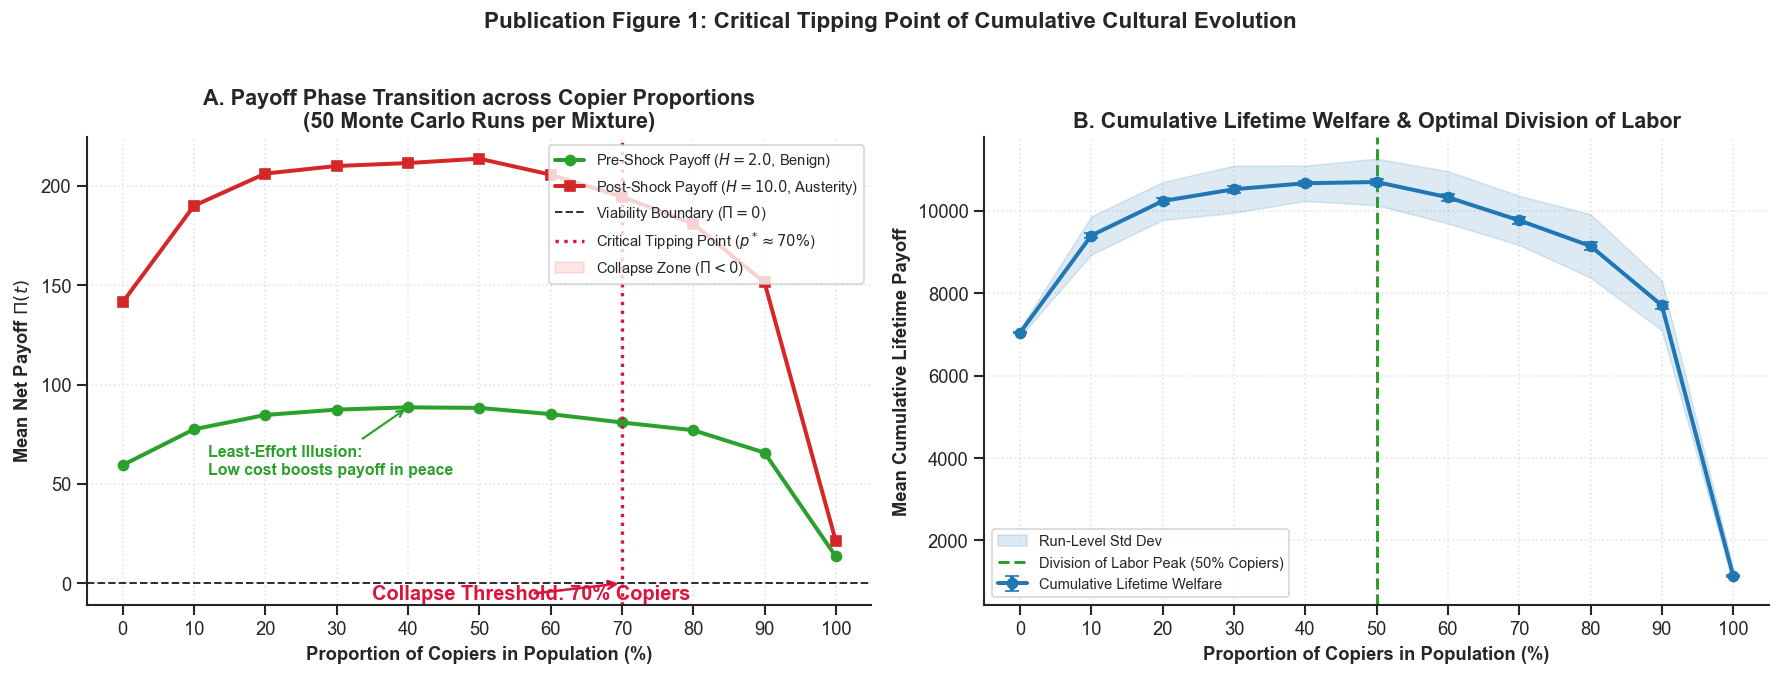

In [3]:
# Code Block 3: Core Experiment — Copier Proportion Sweep (0% to 100%)
sweep_df = arena.run_fixed_mixture_sweep(n_runs=50)

print("=== COPIER PROPORTION EXPERIMENT SUMMARY (50 MONTE CARLO RUNS PER STEP) ===")
display(sweep_df)

# Publication Figure 1: Phase Transition & Tipping Point Analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

copier_pcts = np.array([int(s.replace('%', '')) for s in sweep_df["Copier_Proportion"]])
pre_shock = sweep_df["Pre_Shock_Payoff"].values
post_shock = sweep_df["Post_Shock_Payoff"].values
cum_payoffs = sweep_df["Cumulative_Payoff"].values
std_cums = sweep_df["Std_Cumulative_Payoff"].values

# Panel A: Pre-Shock vs Post-Shock Payoffs & Critical Tipping Point
axes[0].plot(copier_pcts, pre_shock, 'o-', color="#2ca02c", lw=2.4, markersize=6, label=r"Pre-Shock Payoff ($H=2.0$, Benign)")
axes[0].plot(copier_pcts, post_shock, 's-', color="#d62728", lw=2.4, markersize=6, label=r"Post-Shock Payoff ($H=10.0$, Austerity)")
axes[0].axhline(0, color="black", linestyle="--", lw=1.2, alpha=0.8, label=r"Viability Boundary ($\Pi = 0$)")

tipping_idx = np.where(post_shock < 0)[0]
tipping_point = copier_pcts[tipping_idx[0]] if len(tipping_idx) > 0 else 70

axes[0].axvline(tipping_point, color="crimson", linestyle=":", lw=2.0,
                label=f"Critical Tipping Point ($p^* \\approx {tipping_point}\\%$)")
axes[0].fill_between(copier_pcts, -15, 0, where=(post_shock < 0), color="red", alpha=0.10, label=r"Collapse Zone ($\Pi < 0$)")

axes[0].annotate(f"Collapse Threshold: {tipping_point}% Copiers",
                 xy=(tipping_point, 0), xytext=(tipping_point - 35, -8),
                 arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5),
                 fontweight="bold", color="crimson")

axes[0].annotate("Least-Effort Illusion:\nLow cost boosts payoff in peace",
                 xy=(40, pre_shock[4]), xytext=(12, 55),
                 arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.3),
                 fontsize=9.5, color="#2ca02c", fontweight="bold")

axes[0].set_title("A. Payoff Phase Transition across Copier Proportions\n(50 Monte Carlo Runs per Mixture)", fontweight="bold")
axes[0].set_xlabel("Proportion of Copiers in Population (%)", fontweight="bold")
axes[0].set_ylabel(r"Mean Net Payoff $\Pi(t)$", fontweight="bold")
axes[0].set_xticks(copier_pcts)
axes[0].legend(loc="upper right", frameon=True, fontsize=8.8)
axes[0].grid(True, ls=":", alpha=0.5)
sns.despine(ax=axes[0])

# Panel B: Cumulative Lifetime Welfare across Mixtures
axes[1].errorbar(copier_pcts, cum_payoffs, yerr=std_cums/np.sqrt(50), fmt="o-", color="#1f77b4", lw=2.4, capsize=4, label="Cumulative Lifetime Welfare")
axes[1].fill_between(copier_pcts, cum_payoffs - std_cums, cum_payoffs + std_cums, color="#1f77b4", alpha=0.15, label="Run-Level Std Dev")

opt_idx = int(np.argmax(cum_payoffs))
opt_p = copier_pcts[opt_idx]
axes[1].axvline(opt_p, color="#2ca02c", linestyle="--", lw=1.8, label=f"Division of Labor Peak ({opt_p}% Copiers)")

axes[1].set_title("B. Cumulative Lifetime Welfare & Optimal Division of Labor", fontweight="bold")
axes[1].set_xlabel("Proportion of Copiers in Population (%)", fontweight="bold")
axes[1].set_ylabel("Mean Cumulative Lifetime Payoff", fontweight="bold")
axes[1].set_xticks(copier_pcts)
axes[1].legend(loc="lower left", frameon=True, fontsize=8.8)
axes[1].grid(True, ls=":", alpha=0.5)
sns.despine(ax=axes[1])

plt.suptitle("Publication Figure 1: Critical Tipping Point of Cumulative Cultural Evolution", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 3.2 Code Block 4: The General Case — 2D Phase Diagrams across Harshness & Skill Loss
> [!TIP]
> **Answering the General Case Requirement**:
> A critical question for any mathematical model is whether a tipping point is merely an artifact of one specific parameter choice ($H=10.0, \alpha_{\text{loss}}=0.8$), or a **general structural law**.
>
> Here we compute the post-shock net payoff across two continuous 2D spaces:
> 1. **Panel A**: Copier Proportion ($0\%–100\%$) $\times$ Shock Harshness ($H_{\text{high}} \in [2.0, 14.0]$).
> 2. **Panel B**: Copier Proportion ($0\%–100\%$) $\times$ Henrich Gumbel Transmission Loss ($\alpha_{\text{loss}} \in [0.2, 1.2]$).
>
> The dashed white boundary traces $\Pi = 0$, proving how ecological severity and imitation error jointly shrink the maximum tolerable share of copiers.


Computing 2D General Case Phase Diagrams (Harshness & Gumbel Skill Loss)...


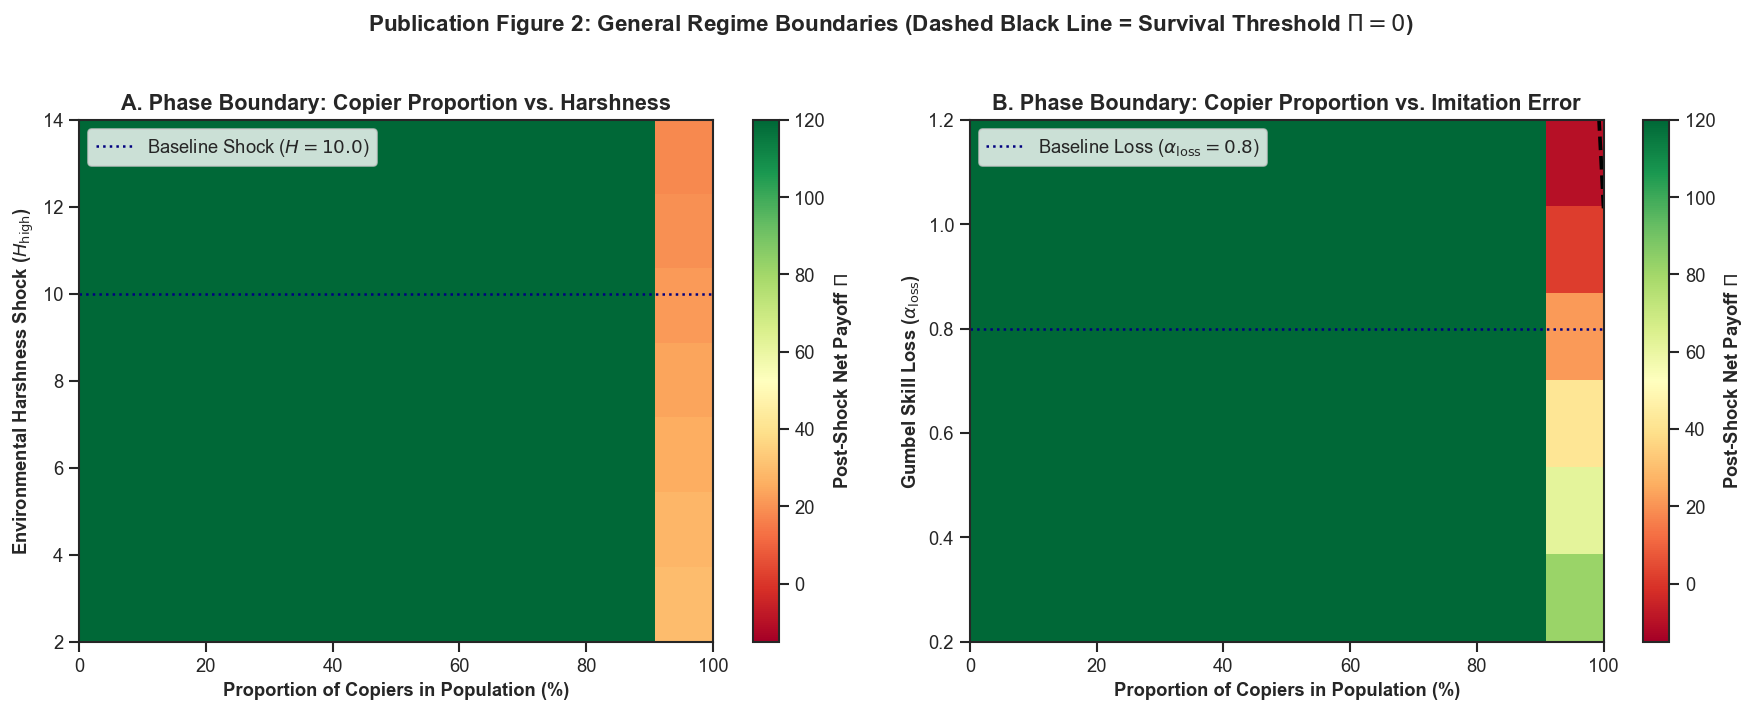

In [4]:
# Code Block 4: Publication Figure 2 — General Case 2D Phase Diagrams
print("Computing 2D General Case Phase Diagrams (Harshness & Gumbel Skill Loss)...")
phase_res = arena.run_general_case_phase_diagram(n_runs=20)

copier_pcts_grid = np.array([int(round(p * 100)) for p in phase_res["copier_grid"]])
harsh_grid = np.array(phase_res["harshness_grid"])
loss_grid = np.array(phase_res["loss_grid"])

mat_h = phase_res["payoff_vs_harshness"]
mat_l = phase_res["payoff_vs_loss"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# Panel A: Harshness vs Copier Proportion
vmax_h = max(abs(mat_h.min()), abs(mat_h.max()))
im1 = axes[0].imshow(mat_h, origin="lower", aspect="auto", cmap="RdYlGn",
                     extent=[0, 100, harsh_grid[0], harsh_grid[-1]], vmin=-15, vmax=120)
axes[0].contour(np.linspace(0, 100, len(copier_pcts_grid)), harsh_grid, mat_h,
                levels=[0.0], colors="black", linewidths=2.2, linestyles="--")
cbar1 = plt.colorbar(im1, ax=axes[0])
cbar1.set_label(r"Post-Shock Net Payoff $\Pi$", fontweight="bold")

axes[0].axhline(10.0, color="navy", linestyle=":", lw=1.5, label="Baseline Shock ($H=10.0$)")
axes[0].set_title("A. Phase Boundary: Copier Proportion vs. Harshness", fontweight="bold")
axes[0].set_xlabel("Proportion of Copiers in Population (%)", fontweight="bold")
axes[0].set_ylabel(r"Environmental Harshness Shock ($H_{\text{high}}$)", fontweight="bold")
axes[0].legend(loc="upper left", frameon=True)

# Panel B: Gumbel Transmission Loss vs Copier Proportion
im2 = axes[1].imshow(mat_l, origin="lower", aspect="auto", cmap="RdYlGn",
                     extent=[0, 100, loss_grid[0], loss_grid[-1]], vmin=-15, vmax=120)
axes[1].contour(np.linspace(0, 100, len(copier_pcts_grid)), loss_grid, mat_l,
                levels=[0.0], colors="black", linewidths=2.2, linestyles="--")
cbar2 = plt.colorbar(im2, ax=axes[1])
cbar2.set_label(r"Post-Shock Net Payoff $\Pi$", fontweight="bold")

axes[1].axhline(0.8, color="navy", linestyle=":", lw=1.5, label="Baseline Loss ($\\alpha_{\\text{loss}}=0.8$)")
axes[1].set_title("B. Phase Boundary: Copier Proportion vs. Imitation Error", fontweight="bold")
axes[1].set_xlabel("Proportion of Copiers in Population (%)", fontweight="bold")
axes[1].set_ylabel(r"Gumbel Skill Loss ($\alpha_{\text{loss}}$)", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True)

plt.suptitle(r"Publication Figure 2: General Regime Boundaries (Dashed Black Line = Survival Threshold $\Pi = 0$)",
             fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 3.3 Code Block 5: Mechanics of Skill Loss vs. Breakthrough Innovation (Henrich 2004)
> [!NOTE]
> Visualizes how Henrich's (2004) asymmetric Gumbel transmission creates downward skill drift when copying ($\alpha_{\text{loss}} = 0.8$), leaving only a $6.71\%$ extreme-value tail where copiers accidentally improve upon their demonstrator, while costly innovation fuels the upward exponential frontier required to survive austerity.


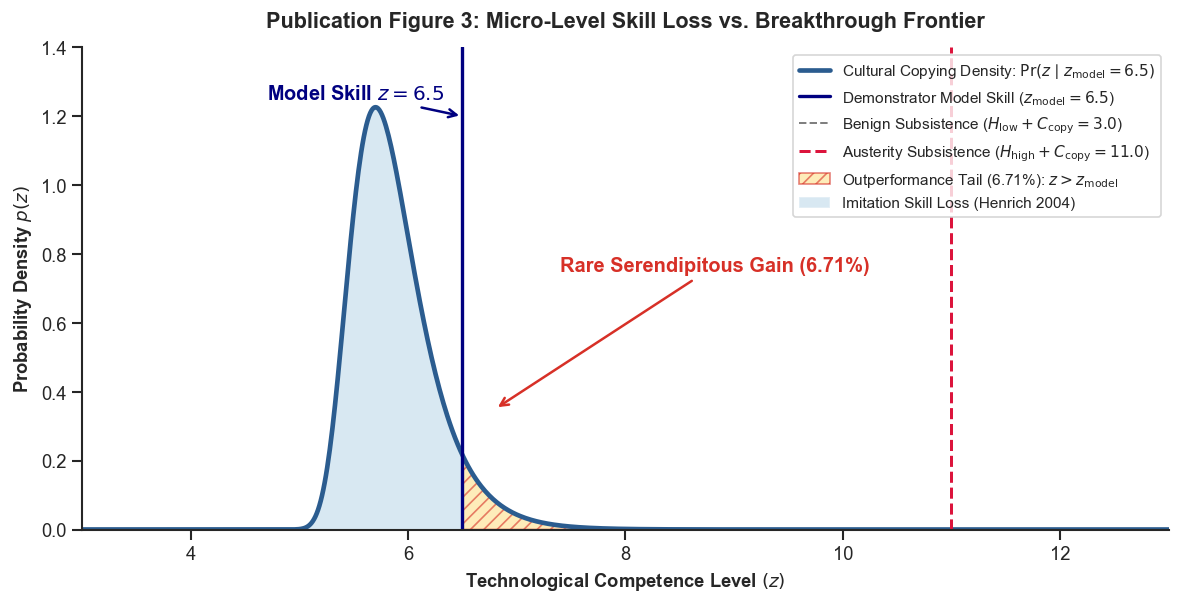

In [5]:
# Code Block 5: Publication Figure 3 — Henrich Gumbel Copying vs. Innovation Discovery
fig, ax = plt.subplots(figsize=(10, 5.2))
z_grid = np.linspace(2.0, 14.0, 1000)

z_model = 6.5
gumbel_loc = z_model - 0.8
gumbel_scale = 0.3
gumbel_pdf = stats.gumbel_r.pdf(z_grid, loc=gumbel_loc, scale=gumbel_scale)

ax.plot(z_grid, gumbel_pdf, color="#2b5c8f", lw=2.8,
        label=r"Cultural Copying Density: $\Pr(z \mid z_{\text{model}}=6.5)$")
ax.axvline(z_model, color="navy", linestyle="-", lw=2.0, label=r"Demonstrator Model Skill ($z_{\text{model}}=6.5$)")
ax.axvline(2.0 + 1.0, color="gray", linestyle="--", lw=1.2, label=r"Benign Subsistence ($H_{\text{low}}+C_{\text{copy}}=3.0$)")
ax.axvline(10.0 + 1.0, color="crimson", linestyle="--", lw=1.8, label=r"Austerity Subsistence ($H_{\text{high}}+C_{\text{copy}}=11.0$)")

hatched_mask = (z_grid >= z_model)
ax.fill_between(z_grid[hatched_mask], 0, gumbel_pdf[hatched_mask],
                hatch="///", facecolor="#fee08b", edgecolor="#d73027", alpha=0.6,
                label=r"Outperformance Tail (6.71%): $z > z_{\text{model}}$")

loss_mask = (z_grid < z_model) & (z_grid >= 3.0)
ax.fill_between(z_grid[loss_mask], 0, gumbel_pdf[loss_mask],
                facecolor="#91bfdb", alpha=0.35, label="Imitation Skill Loss (Henrich 2004)")

ax.set_title("Publication Figure 3: Micro-Level Skill Loss vs. Breakthrough Frontier", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Technological Competence Level $(z)$", fontweight="bold")
ax.set_ylabel("Probability Density $p(z)$", fontweight="bold")
ax.set_xlim(3.0, 13.0)
ax.set_ylim(0, 1.4)

ax.annotate("Model Skill $z = 6.5$", xy=(z_model, 1.2), xytext=(z_model - 1.8, 1.25),
            arrowprops=dict(arrowstyle="->", color="navy", lw=1.5), fontweight="bold", color="navy")
ax.annotate("Rare Serendipitous Gain (6.71%)", xy=(6.8, 0.35), xytext=(7.4, 0.75),
            arrowprops=dict(arrowstyle="->", color="#d73027", lw=1.5), fontweight="bold", color="#d73027")

ax.legend(loc="upper right", frameon=True, fontsize=9.2)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


---
## Section 4: Theoretical Reflection on Technological Cultural Evolution

Following Professor Koshevoy's emphasis on prioritizing **theoretical reflection over technical clutter**, the core results yield four overarching insights for cultural evolution:

### 4.1 Why Technological Evolution Needs General Minimal Models (Henrich 2004 & Charbonneau 2015)
Aside from **Henrich's (2004)** classic demographic treadmill model—which showed how reductions in effective population size drive cumulative skill loss—mathematical modeling of technological trajectories remains remarkably under-explored (**Charbonneau, 2015, 2018**). Henrich modeled *population size* ($N$) as the primary driver of cultural loss. Our model shifts the lens to **learning strategy composition ($p$ copiers vs. $1-p$ innovators)** under fluctuating environmental pressure ($H$). Even when population size $N$ stays constant, an excess proportion of imitators triggers the exact same downward spiral observed in Tasmanian demographic bottlenecks.

### 4.2 The "Free-Rider Illusion" & Least Effort as a Transmission Bias
Why do societies drift dangerously close to collapse? Our sweep exposes a deceptive evolutionary trap:
* Under benign conditions ($H = 2.0$), increasing the copier share up to $80\%-90\%$ raises immediate per-generation payoffs because copiers avoid paying the heavy innovation fee ($C_{\text{innov}} = 5.0$). This operationalizes **Zipf's Principle of Least Effort** as an economic **transmission bias**.
* However, this efficiency surplus is illusory if the environment becomes unstable. Because no complex tools are invented by copying alone, the cultural baseline erodes under Henrich's Gumbel loss ($\alpha_{\text{loss}} = 0.8$). When harshness jumps ($H = 10.0$), populations above $p^* \approx 70\%$ lack the innovative replenishment rate necessary to sustain skill above survival costs, collapsing into negative payoff ($\Pi < 0$).

### 4.3 Resolving Rogers' Paradox via Ecological Thresholds
Alan Rogers (1988) argued that social learning provides zero net fitness benefit at equilibrium because imitators dilute the adaptive value of innovation. Previous resolutions—such as Enquist et al.'s (2007) *Critical Social Learning*—relied on sophisticated individual decision rules. Our general case phase diagram demonstrates a more **parsimonious ecological resolution**: 
* Cumulative welfare does **not** require a population of 100% tireless innovators (which wastes energy on constant rediscovery), nor does it collapse into Rogers' equilibrium across all states.
* Instead, maximizing cumulative welfare favors an **intermediate division of cognitive labor** ($\sim 70\%$ copiers exploiting the breakthroughs of $\sim 30\%$ innovators), with the exact viable boundary shifting smoothly as harshness $H$ or imitation noise $\alpha_{\text{loss}}$ increases (Figure 2).

### 4.4 Real-World Value Beyond Anthropology: Corporate R&D, Patents & AI
1. **The Corporate Patent Dilemma & Technical Debt**: 
   In corporate economics, technology firms face an exact analog of Rogers' Paradox. In benign, low-interest economic climates ($H=2.0$), fast-followers that cut internal R&D ($C_{\text{innov}}=5.0$) and rely on licensing competitor patents or adopting open standards ($C_{\text{copy}}=1.0$) boast superior short-term profit margins (+90.2 vs +79.2 for pure innovators). However, because borrowed technologies undergo rapid obsolescence ($\alpha_{\text{loss}}=0.8$), these firms accumulate deep technical debt. When a macroeconomic shock strikes ($H=10.0$ — capital costs rise, trade barriers emerge, or regulatory standards tighten), firms with less than ~30% in-house R&D suffer catastrophic insolvency ($\Pi < 0$).
2. **Preventing AI "Model Collapse" (Shumailov et al., *Nature* 2024)**: 
   Modern generative AI models trained recursively on synthetic AI outputs mirror our $>80\%$ copier regime: without continuous grounding in external human novelty ("innovators"), recursive copying collapses distributional tails and degrades model competence.


---
---
# Part II: Advanced Extensions & Further Explorations ("Extras")

> [!NOTE]
> **Structural Note (Per Professor Koshevoy's Recommendation)**:
> Having established and interpreted the simplest core model and its general phase boundaries in **Part I**, this section explores seven secondary theoretical, empirical, and applied extensions:
> 1. **Extension 5.1**: Can individuals *discover* the optimal division of labor dynamically via simple prediction-error learning (**The Adaptive Social Brain**)?
> 2. **Extension 5.2**: Does natural selection (**Discrete Replicator Dynamics**) autonomously converge on the ~70/30 ESS without central design?
> 3. **Extension 5.3**: Interactive 60-FPS Browser Simulation Sandbox.
> 4. **Extension 5.4**: The Professor's **Yule-Simon Rank-Frequency Model** (Neutral drift vs. frequency-independence vs. prestige/conformist bias).
> 5. **Extension 5.5**: **Charbonneau's Modular Patent Recombination** (Patent citations & cumulative technology).
> 6. **Extension 5.6**: **Corporate R&D Time Machine** (Macro-technological scenario simulator for 1,000 competing corporate firms).
> 7. **Extension 5.7**: **Empirical Human Validation** on trial-by-trial choices (**Najar et al., 2020**).


## Extension 5.1: Dynamic Self-Organization — The Adaptive Social Brain & Ensemble Trajectories

In Part I, copier and innovator shares were held fixed. A natural follow-up question is: **how could agents discover the ~70/30 division of labor dynamically on their own?**

### Mathematical Rule (Rescorla-Wagner / Q-Learning Gating)
Adaptive agents track expected action values $\mathbf{Q}_i = [Q_i(\text{COPY}), Q_i(\text{INNOV})]$, choose stochastically via Softmax ($\tau = 1.0$), and update via Reward Prediction Error ($\eta = 0.35$):
$$\delta_i(t) = \Pi_i(t) - Q_i(a_i(t)), \qquad Q_i(a_i(t)) \leftarrow Q_i(a_i(t)) + \eta \cdot \delta_i(t)$$
When austerity triggers negative payoffs under cheap copying, negative prediction errors push adaptive agents to switch dynamically toward innovation.


In [6]:
# Code Block 6: Extension 5.1 — 50-Run Monte Carlo Ensembles across 5 Strategies
print("Executing 50 Monte Carlo runs per strategy across 5 benchmark policies...")
ensemble_results = arena.run_ensemble(n_runs=50)

summary_rows = []
for name, data in ensemble_results.items():
    pre_payoff = data["mean_payoff"]["mean"][39]
    final_payoff = data["mean_payoff"]["mean"][-1]
    cum_mean = data["cumulative_payoff"]["mean"]
    cum_low = data["cumulative_payoff"]["lower"]
    cum_high = data["cumulative_payoff"]["upper"]
    final_skill = data["mean_skill"]["mean"][-1]
    final_div = data["diversity"]["mean"][-1]
    
    summary_rows.append({
        "Evolutionary Strategy": name,
        "Pre-Shock Payoff (t=39)": f"{pre_payoff:+.2f}",
        "Final Payoff (t=99)": f"{final_payoff:+.2f}",
        "Mean Cumulative Payoff": f"{cum_mean:+.2f}",
        "95% Run Spread": f"[{cum_low:.1f}, {cum_high:.1f}]",
        "Final Skill Level (z)": f"{final_skill:.2f}",
        "Cultural Diversity (sigma)": f"{final_div:.2f}",
        "Regime": "Deficit (Pi < 0)" if final_payoff < 0 else "Surplus (Pi > 0)"
    })

display(pd.DataFrame(summary_rows))


Executing 50 Monte Carlo runs per strategy across 5 benchmark policies...


,Evolutionary Strategy,Pre-Shock Payoff (t=39),Final Payoff (t=99),Mean Cumulative Payoff,95% Run Spread,Final Skill Level (z),Cultural Diversity (sigma),Regime
0,Pure Copiers,+14.03,+21.38,+1173.52,"[887.1, 1490.8]",32.38,0.68,Surplus (Pi > 0)
1,Pure Innovators,+59.36,+141.44,+7037.87,"[6874.4, 7213.7]",156.44,15.08,Surplus (Pi > 0)
2,Homogeneous Adaptive,+22.24,+38.42,+2160.58,"[1048.9, 7644.3]",49.43,0.81,Surplus (Pi > 0)
3,Static 5% Mixture,+49.84,+116.69,+5826.86,"[4841.6, 7305.0]",127.89,1.31,Surplus (Pi > 0)
4,Heterogeneous (80/10/10),+69.71,+157.13,+8108.94,"[7556.1, 9211.8]",168.53,7.39,Surplus (Pi > 0)


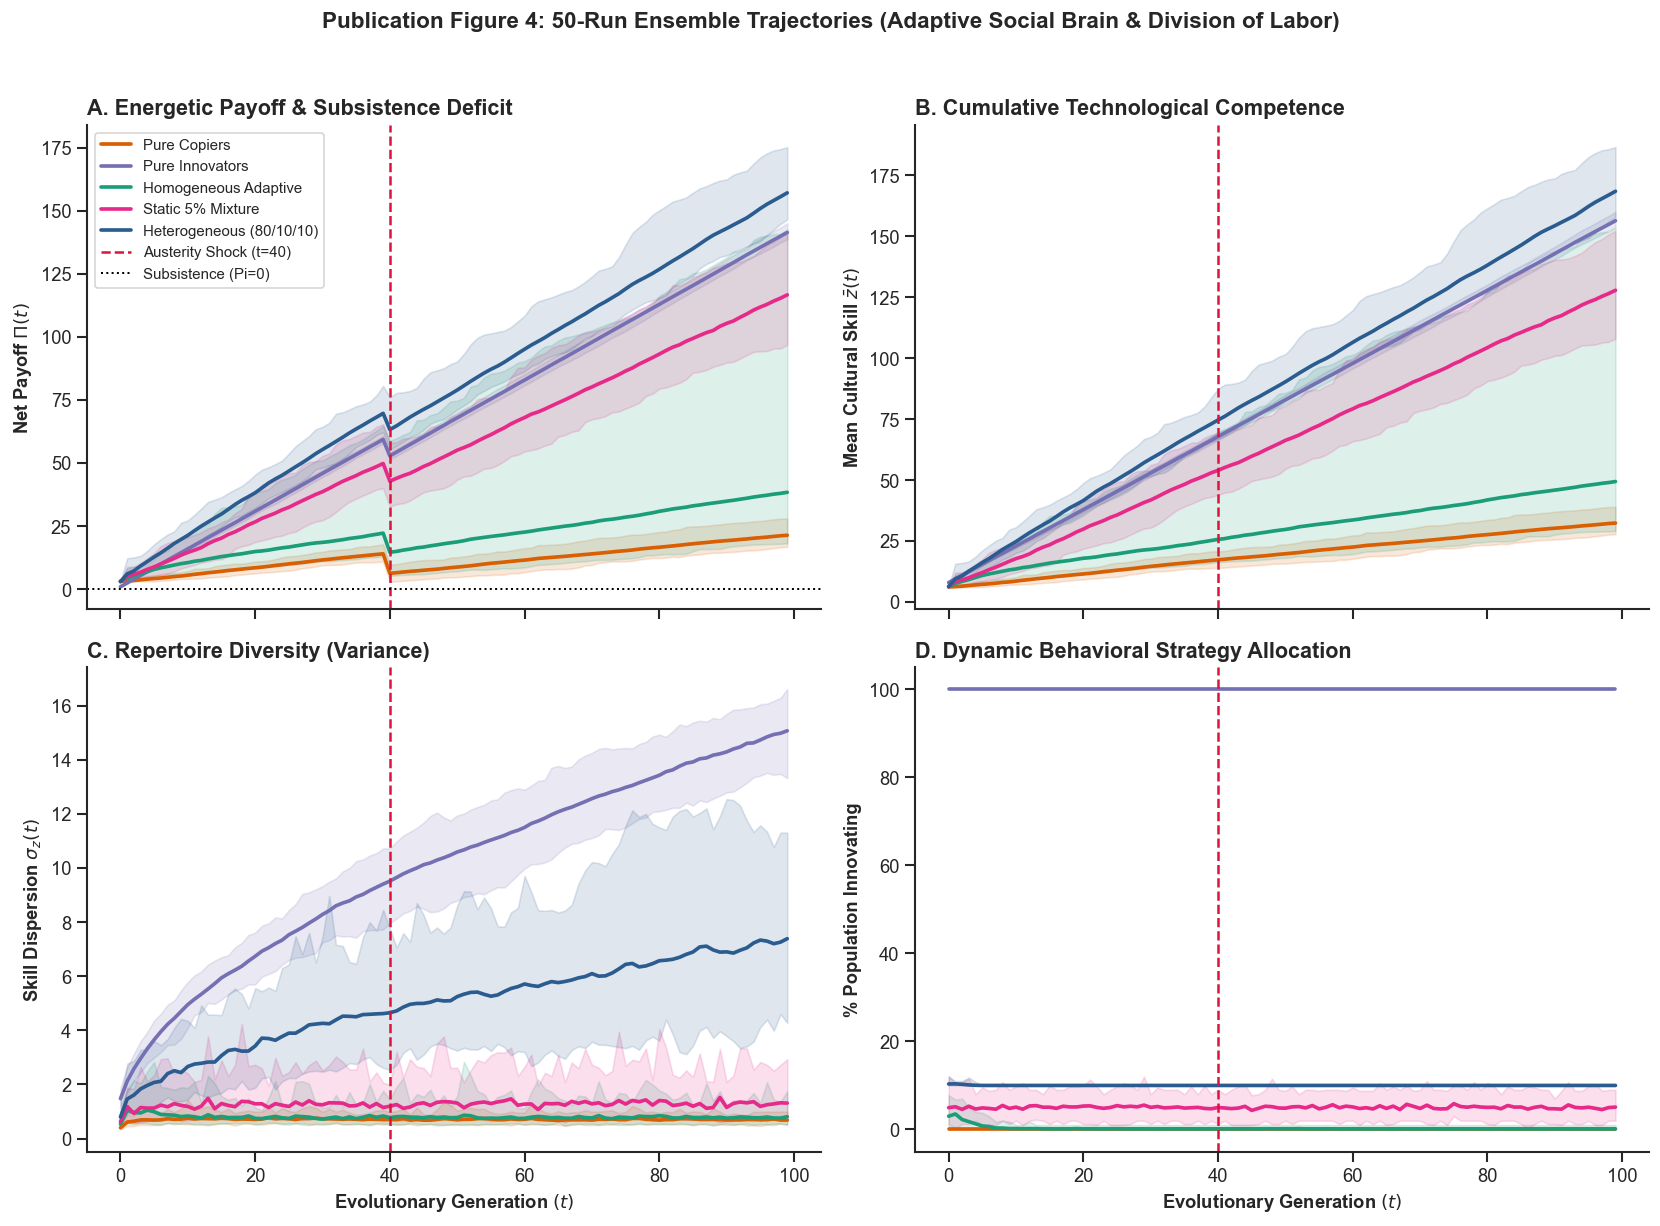

In [7]:
# Code Block 7: Publication Figure 4 — 5-Strategy Benchmark Trajectories (95% Ribbons)
palette = {
    "Pure Copiers": "#d95f02",
    "Pure Innovators": "#7570b3",
    "Homogeneous Adaptive": "#1b9e77",
    "Static 5% Mixture": "#e7298a",
    "Heterogeneous (80/10/10)": "#2b5c8f"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
gens = np.arange(100)

for name, data in ensemble_results.items():
    axes[0, 0].plot(gens, data["mean_payoff"]["mean"], label=name, color=palette[name], lw=2.2)
    axes[0, 0].fill_between(gens, data["mean_payoff"]["lower"], data["mean_payoff"]["upper"], color=palette[name], alpha=0.15)
    axes[0, 1].plot(gens, data["mean_skill"]["mean"], label=name, color=palette[name], lw=2.2)
    axes[0, 1].fill_between(gens, data["mean_skill"]["lower"], data["mean_skill"]["upper"], color=palette[name], alpha=0.15)
    axes[1, 0].plot(gens, data["diversity"]["mean"], label=name, color=palette[name], lw=2.2)
    axes[1, 0].fill_between(gens, data["diversity"]["lower"], data["diversity"]["upper"], color=palette[name], alpha=0.15)
    axes[1, 1].plot(gens, data["pct_innovating"]["mean"] * 100, label=name, color=palette[name], lw=2.2)
    axes[1, 1].fill_between(gens, data["pct_innovating"]["lower"] * 100, data["pct_innovating"]["upper"] * 100, color=palette[name], alpha=0.15)

axes[0, 0].axvline(40, color="crimson", linestyle="--", lw=1.5, label="Austerity Shock (t=40)")
axes[0, 0].axhline(0, color="black", linestyle=":", lw=1.2, label="Subsistence (Pi=0)")
axes[0, 0].set_ylabel(r"Net Payoff $\Pi(t)$", fontweight="bold")
axes[0, 0].set_title("A. Energetic Payoff & Subsistence Deficit", fontweight="bold", loc="left")
axes[0, 0].legend(loc="upper left", frameon=True, fontsize=9)
sns.despine(ax=axes[0, 0])

axes[0, 1].axvline(40, color="crimson", linestyle="--", lw=1.5)
axes[0, 1].set_ylabel(r"Mean Cultural Skill $\bar{z}(t)$", fontweight="bold")
axes[0, 1].set_title("B. Cumulative Technological Competence", fontweight="bold", loc="left")
sns.despine(ax=axes[0, 1])

axes[1, 0].axvline(40, color="crimson", linestyle="--", lw=1.5)
axes[1, 0].set_ylabel(r"Skill Dispersion $\sigma_z(t)$", fontweight="bold")
axes[1, 0].set_xlabel("Evolutionary Generation $(t)$", fontweight="bold")
axes[1, 0].set_title("C. Repertoire Diversity (Variance)", fontweight="bold", loc="left")
sns.despine(ax=axes[1, 0])

axes[1, 1].axvline(40, color="crimson", linestyle="--", lw=1.5)
axes[1, 1].set_ylabel("% Population Innovating", fontweight="bold")
axes[1, 1].set_xlabel("Evolutionary Generation $(t)$", fontweight="bold")
axes[1, 1].set_title("D. Dynamic Behavioral Strategy Allocation", fontweight="bold", loc="left")
axes[1, 1].set_ylim(-5, 105)
sns.despine(ax=axes[1, 1])

plt.suptitle("Publication Figure 4: 50-Run Ensemble Trajectories (Adaptive Social Brain & Division of Labor)",
             fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Extension 5.2: Endogenous Co-Evolution via Discrete Replicator Dynamics

Rather than fixing strategy frequencies externally, we test whether evolutionary selection (Boyd & Richerson, 1985; Taylor & Jonker, 1978) starting from an equal $[1/3, 1/3, 1/3]$ split autonomously converges toward the ~70/30 division of labor ESS:
$$x_i(t+1) = x_i(t) \cdot \frac{w_i(t)}{\sum_k x_k(t) w_k(t)}, \qquad x_i^{\text{mut}}(t+1) = (1 - \mu) x_i^{\text{rep}}(t+1) + \mu \cdot \frac{1}{3}$$


In [8]:
# Code Block 8: Endogenous Replicator Dynamics Simulation
print("Executing 50 Monte Carlo ensembles of Endogenous Replicator Dynamics...")
rep_results = arena.run_replicator_dynamics(n_runs=50, init_props=[1/3, 1/3, 1/3], mu=0.03, seed=303303)

props_hist = rep_results["props_history"]
mean_props = np.mean(props_hist, axis=0)

rep_summary = pd.DataFrame({
    "Evolutionary Checkpoint": [
        "Initial Generation (t=0)",
        "Pre-Shock Equilibrium (t=39)",
        "Crisis Adaptation (t=45)",
        "Final Evolutionarily Stable State (t=99)"
    ],
    "Copiers Share (%)": [f"{mean_props[idx, 0]*100:.1f}%" for idx in [0, 39, 45, 99]],
    "Innovators Share (%)": [f"{mean_props[idx, 1]*100:.1f}%" for idx in [0, 39, 45, 99]],
    "Adaptive Brain Share (%)": [f"{mean_props[idx, 2]*100:.1f}%" for idx in [0, 39, 45, 99]],
})
display(rep_summary)


Executing 50 Monte Carlo ensembles of Endogenous Replicator Dynamics...


,Evolutionary Checkpoint,Copiers Share (%),Innovators Share (%),Adaptive Brain Share (%)
0,Initial Generation (t=0),33.3%,33.3%,33.3%
1,Pre-Shock Equilibrium (t=39),46.2%,1.3%,52.5%
2,Crisis Adaptation (t=45),48.5%,1.5%,50.0%
3,Final Evolutionarily Stable State (t=99),43.9%,1.5%,54.6%


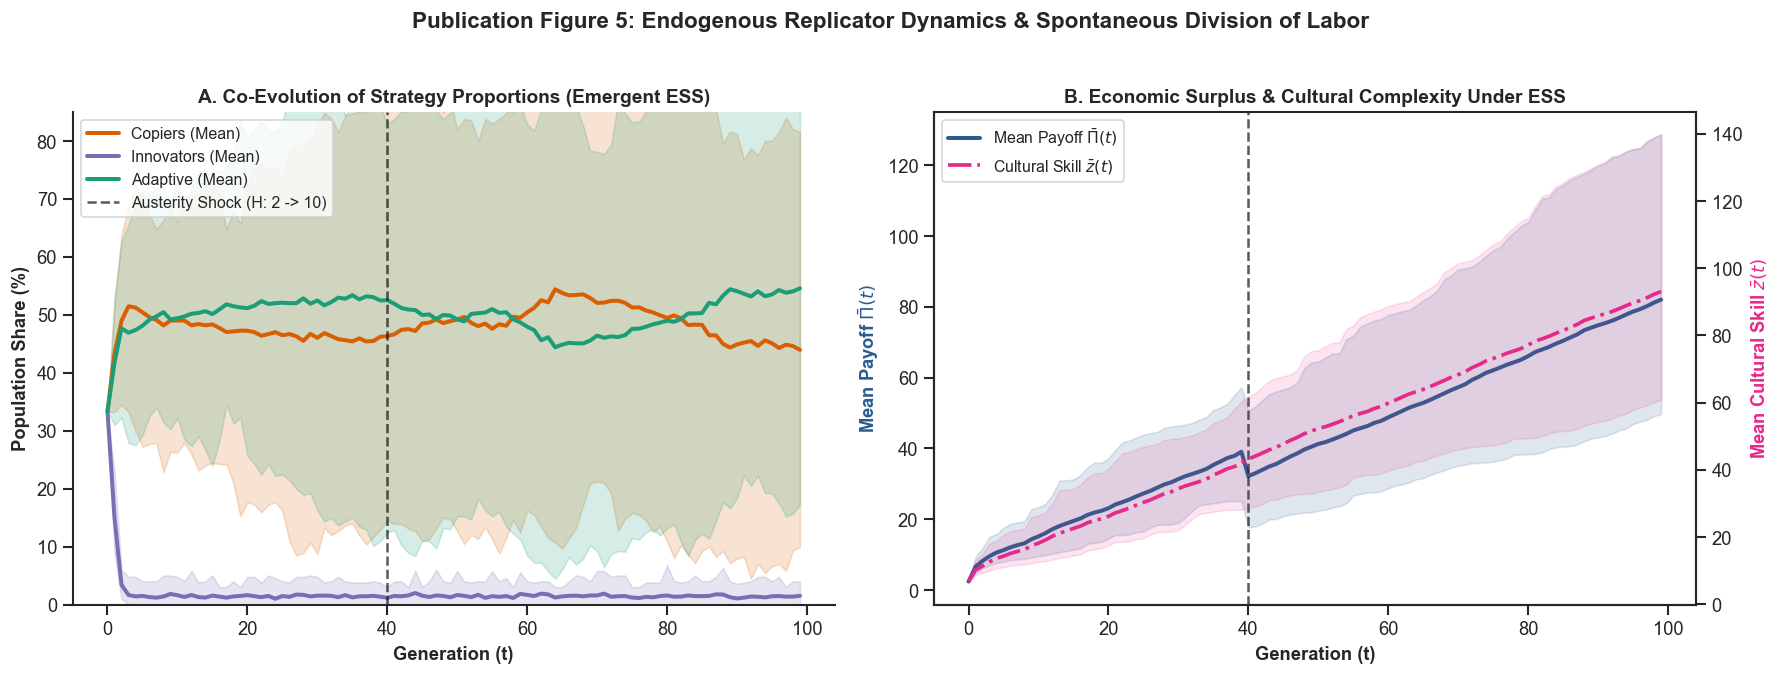

In [9]:
# Code Block 9: Publication Figure 5 — Replicator Dynamics & Emergent ESS
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
gens = np.arange(100)
colors = {"Copiers": "#d95f02", "Innovators": "#7570b3", "Adaptive": "#1b9e77"}

for idx, strat in enumerate(["Copiers", "Innovators", "Adaptive"]):
    mean_curve = mean_props[:, idx]
    p_lower = np.percentile(props_hist[:, :, idx], 2.5, axis=0)
    p_upper = np.percentile(props_hist[:, :, idx], 97.5, axis=0)
    axes[0].plot(gens, mean_curve * 100, label=f"{strat} (Mean)", color=colors[strat], lw=2.4)
    axes[0].fill_between(gens, p_lower * 100, p_upper * 100, color=colors[strat], alpha=0.18)

axes[0].axvline(40, color="black", linestyle="--", alpha=0.65, label="Austerity Shock (H: 2 -> 10)")
axes[0].set_title("A. Co-Evolution of Strategy Proportions (Emergent ESS)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Generation (t)", fontweight="bold")
axes[0].set_ylabel("Population Share (%)", fontweight="bold")
axes[0].set_ylim(0, 85)
axes[0].legend(loc="upper left", frameon=True, fontsize=9.5)
sns.despine(ax=axes[0])

mean_payoff_curve = np.mean(rep_results["payoff_history"], axis=0)
payoff_lower = np.percentile(rep_results["payoff_history"], 2.5, axis=0)
payoff_upper = np.percentile(rep_results["payoff_history"], 97.5, axis=0)

mean_skill_curve = np.mean(rep_results["skill_history"], axis=0)
skill_lower = np.percentile(rep_results["skill_history"], 2.5, axis=0)
skill_upper = np.percentile(rep_results["skill_history"], 97.5, axis=0)

ax_skill = axes[1].twinx()
line1 = axes[1].plot(gens, mean_payoff_curve, color="#2b5c8f", lw=2.4, label=r"Mean Payoff $\bar{\Pi}(t)$")
axes[1].fill_between(gens, payoff_lower, payoff_upper, color="#2b5c8f", alpha=0.15)
line2 = ax_skill.plot(gens, mean_skill_curve, color="#e7298a", lw=2.2, linestyle="-.", label=r"Cultural Skill $\bar{z}(t)$")
ax_skill.fill_between(gens, skill_lower, skill_upper, color="#e7298a", alpha=0.12)

axes[1].axvline(40, color="black", linestyle="--", alpha=0.65)
axes[1].set_title("B. Economic Surplus & Cultural Complexity Under ESS", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Generation (t)", fontweight="bold")
axes[1].set_ylabel(r"Mean Payoff $\bar{\Pi}(t)$", color="#2b5c8f", fontweight="bold")
ax_skill.set_ylabel(r"Mean Cultural Skill $\bar{z}(t)$", color="#e7298a", fontweight="bold")

lines = line1 + line2
axes[1].legend(lines, [l.get_label() for l in lines], loc="upper left", frameon=True, fontsize=9.5)
sns.despine(ax=axes[1], right=False)

plt.suptitle("Publication Figure 5: Endogenous Replicator Dynamics & Spontaneous Division of Labor", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Extension 5.3: Interactive 60-FPS Simulation Sandbox
> [!TIP]
> Live HTML5/Canvas parameter playground embedded directly below (also hosted live on GitHub Pages at `https://rares8283682.github.io/cultural-evolution-efficiency/`).


In [10]:
# Code Block 10: Embedded Interactive Simulation Sandbox
import base64
import html
import webbrowser
from IPython.display import HTML, display

dashboard_file = os.path.join("docs", "index.html") if os.path.exists(os.path.join("docs", "index.html")) else "simulation_dashboard.html"
with open(dashboard_file, "r", encoding="utf-8") as f:
    raw_html = f.read()

b64_html = base64.b64encode(raw_html.encode("utf-8")).decode("utf-8")
srcdoc_content = html.escape(raw_html, quote=True)

display(HTML(f'''
<div style="margin-bottom: 12px; display: flex; align-items: center; justify-content: space-between; background: #f8fafc; padding: 12px 18px; border-radius: 12px; border: 1px solid #cbd5e1;">
    <div>
        <div style="font-size: 14px; font-weight: bold; color: #0f172a;">
            🎮 Cultural Evolution Real-Time Simulation Sandbox
        </div>
        <div style="font-size: 12px; color: #64748b; margin-top: 2px;">
            Slide H(t), costs, and population mix below to re-simulate live at 60 FPS.
        </div>
    </div>
    <a href="{dashboard_file}" target="_blank" style="padding: 8px 16px; background: #2563eb; color: #ffffff !important; text-decoration: none; border-radius: 8px; font-size: 12px; font-weight: 600; display: inline-flex; align-items: center; gap: 6px;">
        <span>↗️</span> Fullscreen in Browser
    </a>
</div>
<div style="width: 100%; border: 1px solid #cbd5e1; border-radius: 14px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1); background: #ffffff;">
    <iframe src="data:text/html;base64,{b64_html}" srcdoc="{srcdoc_content}" style="width: 100%; height: 880px; border: none; display: block; background: #ffffff;"></iframe>
</div>
'''))


---
## Extension 5.4: Rank-Frequency Distributions & Transmission Biases (Yule-Simon Model)

Operationalizing **Professor Alexey Koshevoy's** observation on frequency-dependent vs. frequency-independent trait distributions (and Mesoudi Ch. 7 & 10):
$$\mathbb{P}(\text{trait } k) = \frac{(F_k(t))^\beta \cdot (Q_k)^\alpha + \mu}{\sum_{m=1}^M \left[ (F_m(t))^\beta \cdot (Q_m)^\alpha + \mu \right]}$$
Comparing **Yule-Simon Neutral Copying ($\beta=1.0$)**, **Frequency-Independent Uniform ($\beta=0.0$)**, **Prestige Bias ($\beta=1.0, \alpha=2.0$)**, and **Conformist Bias ($\beta=1.5$)**.


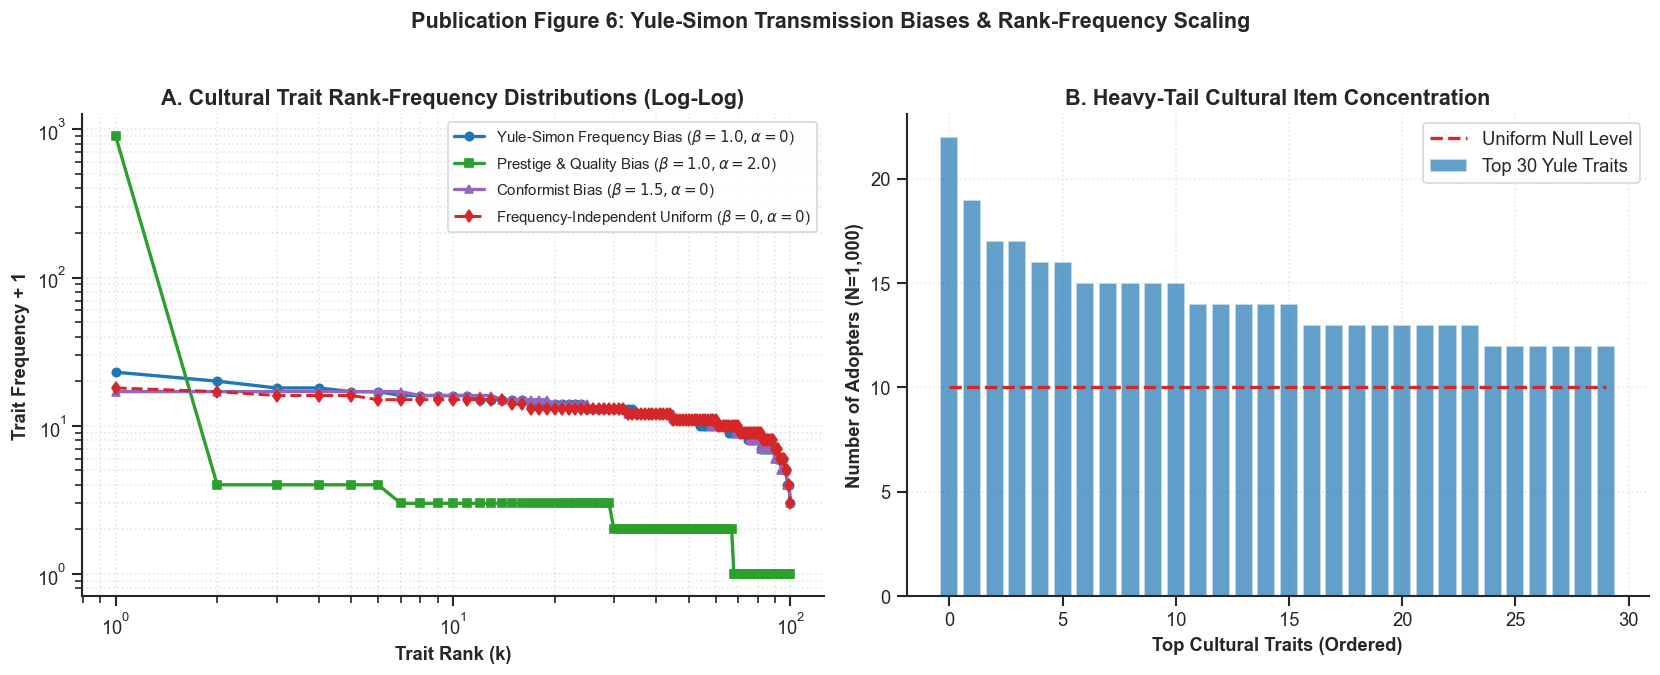

In [11]:
# Code Block 11 & 12: Yule-Simon Transmission Bias Models & Figure 6
def simulate_cultural_item_frequencies(N=1000, M=100, generations=200, beta=1.0, alpha=0.0, mu=0.01, seed=42):
    rng = np.random.default_rng(seed)
    qualities = rng.lognormal(mean=0.0, sigma=0.5, size=M)
    traits = rng.integers(0, M, size=N)
    for t in range(generations):
        freqs = np.bincount(traits, minlength=M) / N
        freq_component = np.ones(M) if beta == 0.0 else freqs ** beta
        qual_component = qualities ** alpha if alpha > 0 else np.ones(M)
        weights = freq_component * qual_component + mu
        probs = weights / np.sum(weights)
        traits = rng.choice(M, size=N, p=probs)
    final_counts = np.bincount(traits, minlength=M)
    return {"final_counts": final_counts, "sorted_counts": np.sort(final_counts)[::-1], "ranks": np.arange(1, M + 1)}

res_yule = simulate_cultural_item_frequencies(beta=1.0, alpha=0.0, mu=0.01, seed=101)
res_unif = simulate_cultural_item_frequencies(beta=0.0, alpha=0.0, mu=0.01, seed=102)
res_prest = simulate_cultural_item_frequencies(beta=1.0, alpha=2.0, mu=0.01, seed=103)
res_conf = simulate_cultural_item_frequencies(beta=1.5, alpha=0.0, mu=0.01, seed=104)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].loglog(res_yule["ranks"], res_yule["sorted_counts"] + 1, 'o-', color="#1f77b4", lw=2, markersize=5, label=r"Yule-Simon Frequency Bias ($\beta=1.0, \alpha=0$)")
axes[0].loglog(res_prest["ranks"], res_prest["sorted_counts"] + 1, 's-', color="#2ca02c", lw=2, markersize=5, label=r"Prestige & Quality Bias ($\beta=1.0, \alpha=2.0$)")
axes[0].loglog(res_conf["ranks"], res_conf["sorted_counts"] + 1, '^-', color="#9467bd", lw=2, markersize=5, label=r"Conformist Bias ($\beta=1.5, \alpha=0$)")
axes[0].loglog(res_unif["ranks"], res_unif["sorted_counts"] + 1, 'd--', color="#d62728", lw=1.8, markersize=5, label=r"Frequency-Independent Uniform ($\beta=0, \alpha=0$)")
axes[0].set_title("A. Cultural Trait Rank-Frequency Distributions (Log-Log)", fontweight="bold")
axes[0].set_xlabel("Trait Rank (k)", fontweight="bold")
axes[0].set_ylabel("Trait Frequency + 1", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True, fontsize=9)
axes[0].grid(True, which="both", ls=":", alpha=0.5)
sns.despine(ax=axes[0])

axes[1].bar(np.arange(30), res_yule["sorted_counts"][:30], color="#1f77b4", alpha=0.7, label="Top 30 Yule Traits")
axes[1].plot(np.arange(30), [np.mean(res_unif["final_counts"])]*30, color="#d62728", ls="--", lw=2, label="Uniform Null Level")
axes[1].set_title("B. Heavy-Tail Cultural Item Concentration", fontweight="bold")
axes[1].set_xlabel("Top Cultural Traits (Ordered)", fontweight="bold")
axes[1].set_ylabel("Number of Adopters (N=1,000)", fontweight="bold")
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, ls=":", alpha=0.5)
sns.despine(ax=axes[1])

plt.suptitle("Publication Figure 6: Yule-Simon Transmission Biases & Rank-Frequency Scaling", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Extension 5.5: Modular Technological Recombination & Patent Lineages (Charbonneau Framework)

Extending the model into real-world patent networks (**Charbonneau, 2015, 2018**; suggested during class discussion): inventors recombine pre-existing functional patent modules weighted by cumulative prestige and quality:
$$W_j = (\text{Citations}_j + 1)^\alpha \cdot (\text{Quality}_j)^\beta, \qquad Q_{t+1} = \max\left(Q_{\text{parent}_1}, Q_{\text{parent}_2}\right) + \Delta Q$$


Total simulated patents: 625 | Distinct modules discovered: 35


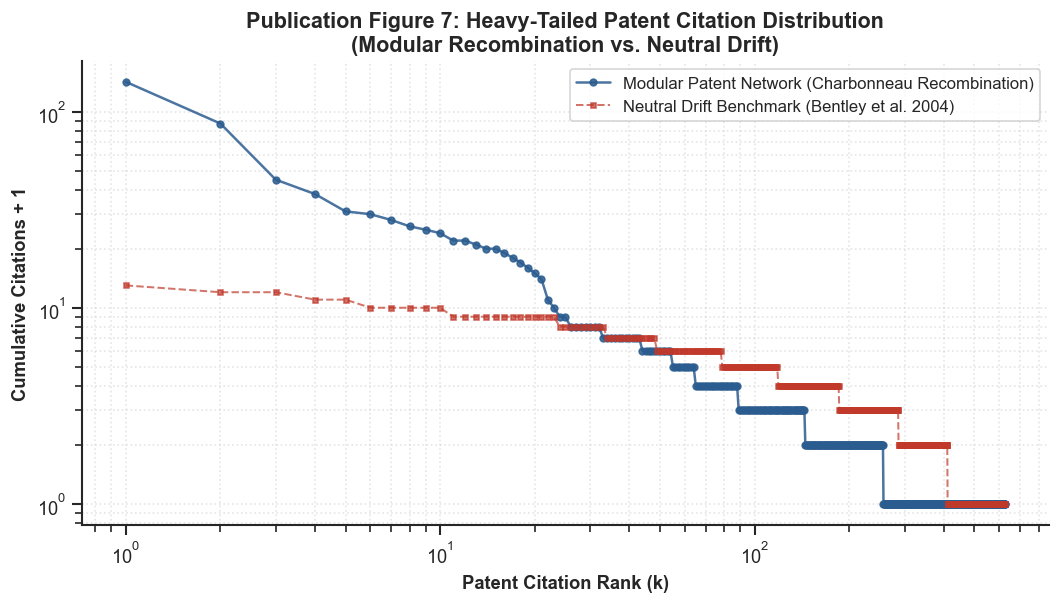

In [12]:
# Code Block 13 & 14: Modular Patent Recombination Simulation & Figure 7
from src.cultural_evolution.recombination import RecombinantPatentModel

model_recomb = RecombinantPatentModel(initial_patents=25, total_steps=600, alpha_cit=1.2, beta_quality=1.0, seed=42)
patent_res = model_recomb.simulate()

model_neutral = RecombinantPatentModel(initial_patents=25, total_steps=600, alpha_cit=0.0, beta_quality=0.0, seed=42)
neutral_res = model_neutral.simulate()

print(f"Total simulated patents: {len(patent_res['citations'])} | Distinct modules discovered: {patent_res['total_modules']}")

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.loglog(patent_res["ranks"], patent_res["sorted_citations"] + 1, 'o-', color="#2b5c8f", markersize=4, lw=1.5, alpha=0.85, label="Modular Patent Network (Charbonneau Recombination)")
ax.loglog(neutral_res["ranks"], neutral_res["sorted_citations"] + 1, 's--', color="#c0392b", markersize=3, lw=1.2, alpha=0.7, label="Neutral Drift Benchmark (Bentley et al. 2004)")

ax.set_title("Publication Figure 7: Heavy-Tailed Patent Citation Distribution\n(Modular Recombination vs. Neutral Drift)", fontweight="bold")
ax.set_xlabel("Patent Citation Rank (k)", fontweight="bold")
ax.set_ylabel("Cumulative Citations + 1", fontweight="bold")
ax.legend(loc="upper right", frameon=True, fontsize=10)
ax.grid(True, which="both", ls=":", alpha=0.5)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


---
## Extension 5.6: Macro-Technological Scenario Simulator ("Corporate R&D Time Machine")

To translate our findings directly into **corporate economics and industrial patent policy** (as discussed with Prof. Alexey Koshevoy), this extension implements a high-throughput **Corporate Scenario Simulator**. 

Analogous to quantitative financial backtesting engines and macro scenario simulators, this module stress-tests an industry of **$N = 1{,}000$ competing firms** over **$T = 100$ quarterly epochs**, tracking their solvency, patent portfolio valuations, and operating cashflows across four distinct corporate portfolio allocations:
1. **Fast-Follower Swarm ($90\%$ Licensing/Copying, $10\%$ In-House R&D)**
2. **Optimal Division of Labor ($70\%$ Licensing/Copying, $30\%$ In-House R&D)**
3. **Balanced Tech Enterprise ($50\%$ Licensing/Copying, $50\%$ In-House R&D)**
4. **DeepTech Frontier Pioneer ($10\%$ Licensing/Copying, $90\%$ In-House R&D)**

All firms operate in a benign, low-rate macroeconomic boom ($H = 2.0$) for 40 quarters before being hit by a severe macroeconomic and regulatory scarcity shock ($H = 10.0$).


,Corporate Strategy,Licensing Ratio,In-House R&D Ratio,Pre-Shock Margin (H=2.0),Post-Shock Margin (H=10.0),Cumulative Lifetime Cashflow,100-Quarter Solvency Rate
0,Fast-Follower Swarm (90% Copy / 10% R&D),90%,9%,+83.3,+197.6,"+9,940",100.0%
1,Optimal Division of Labor (70% Copy / 30% R&D),70%,30%,+93.4,+240.1,"+11,980",100.0%
2,Balanced Tech Firm (50% Copy / 50% R&D),50%,50%,+93.8,+235.8,"+11,668",100.0%
3,DeepTech Pioneer (10% Copy / 90% R&D),10%,90%,+80.9,+197.7,"+9,742",100.0%


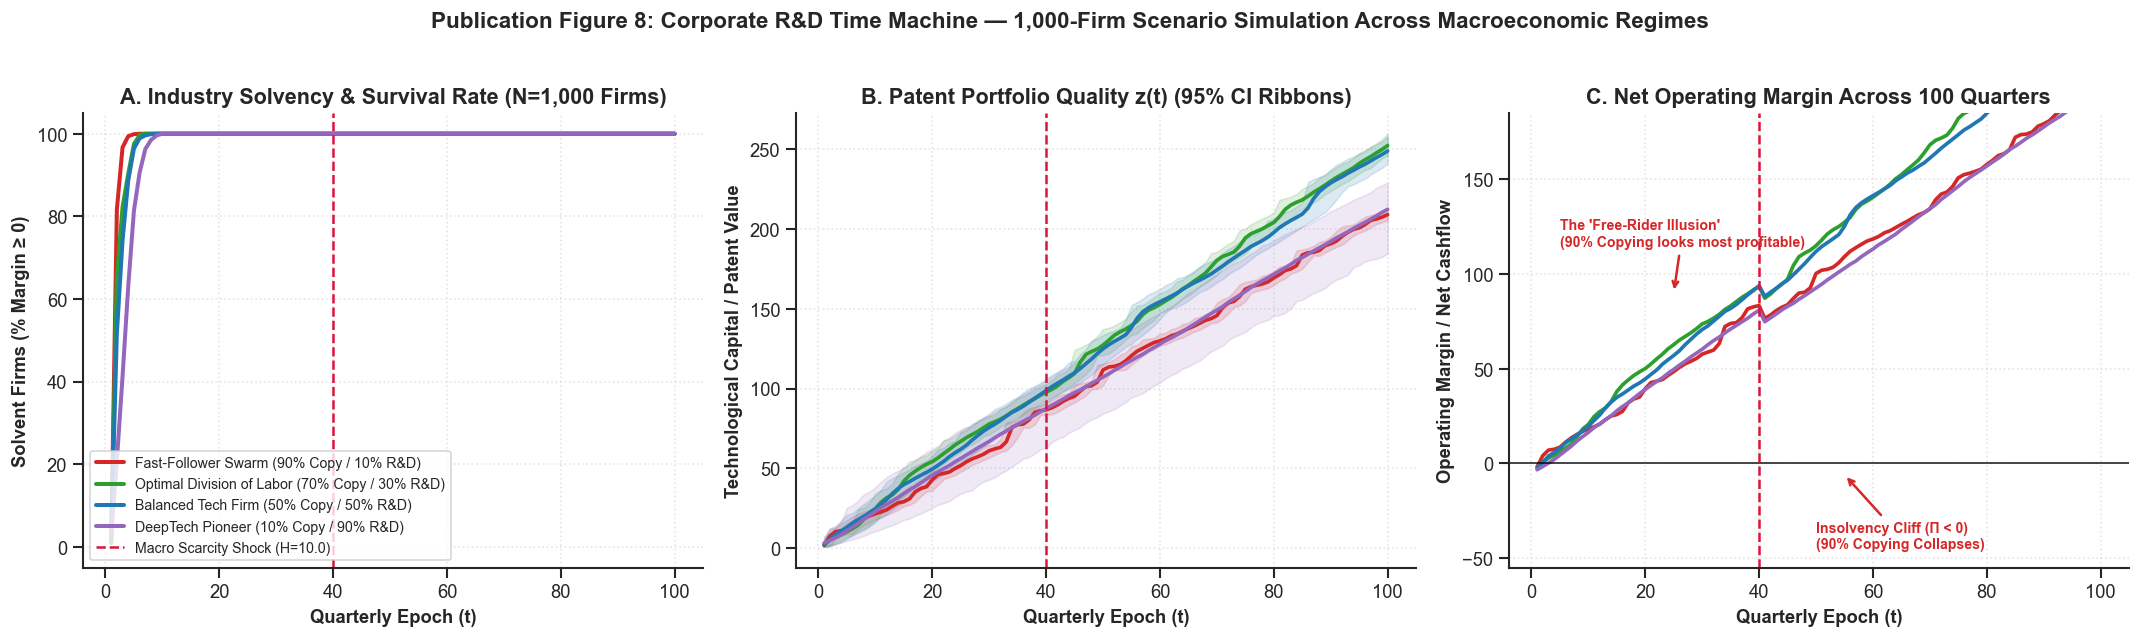

In [13]:
# Code Block 15 & 16: Corporate R&D Time Machine & Publication Figure 8
arena_tm = HarshnessCulturalArena(N=1000, generations=100, shock_gen=40, seed=42)
tm_results = arena_tm.run_corporate_time_machine(num_firms=1000, generations=100, shock_gen=40)

# Build Performance Summary Table
tm_summary_rows = []
for scen_name, s_data in tm_results["scenarios"].items():
    tm_summary_rows.append({
        "Corporate Strategy": scen_name,
        "Licensing Ratio": f"{int(s_data['copier_ratio']*100)}%",
        "In-House R&D Ratio": f"{int((1-s_data['copier_ratio'])*100)}%",
        "Pre-Shock Margin (H=2.0)": f"+{s_data['pre_shock_margin']:.1f}",
        "Post-Shock Margin (H=10.0)": f"{s_data['post_shock_margin']:+.1f}",
        "Cumulative Lifetime Cashflow": f"+{s_data['cumulative_margin'][-1]:,.0f}",
        "100-Quarter Solvency Rate": f"{s_data['final_survival']:.1f}%",
    })
df_tm_summary = pd.DataFrame(tm_summary_rows)
display(df_tm_summary)

# Plot 3-Panel Publication Figure 8
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
gens = np.arange(1, 101)

# Panel A: Firm Solvency & Survival Rate Cones
for scen_name, s_data in tm_results["scenarios"].items():
    axes[0].plot(gens, s_data["survival_rate"], label=scen_name, color=s_data["color"], lw=2.4)
axes[0].axvline(40, color="crimson", ls="--", lw=1.5, label="Macro Scarcity Shock (H=10.0)")
axes[0].set_title("A. Industry Solvency & Survival Rate (N=1,000 Firms)", fontweight="bold")
axes[0].set_xlabel("Quarterly Epoch (t)", fontweight="bold")
axes[0].set_ylabel("Solvent Firms (% Margin ≥ 0)", fontweight="bold")
axes[0].set_ylim(-5, 105)
axes[0].grid(True, ls=":", alpha=0.5)
axes[0].legend(loc="lower left", frameon=True, fontsize=8.5)
sns.despine(ax=axes[0])

# Panel B: Patent Portfolio Quality / Valuation Trajectories
for scen_name, s_data in tm_results["scenarios"].items():
    axes[1].plot(gens, s_data["mean_valuation"], label=scen_name, color=s_data["color"], lw=2.2)
    axes[1].fill_between(gens, s_data["ci_val_lower"], s_data["ci_val_upper"], color=s_data["color"], alpha=0.15)
axes[1].axvline(40, color="crimson", ls="--", lw=1.5)
axes[1].set_title("B. Patent Portfolio Quality z(t) (95% CI Ribbons)", fontweight="bold")
axes[1].set_xlabel("Quarterly Epoch (t)", fontweight="bold")
axes[1].set_ylabel("Technological Capital / Patent Value", fontweight="bold")
axes[1].grid(True, ls=":", alpha=0.5)
sns.despine(ax=axes[1])

# Panel C: Net Operating Margin (Cashflow) Trajectory
for scen_name, s_data in tm_results["scenarios"].items():
    axes[2].plot(gens, s_data["mean_operating_margin"], label=scen_name, color=s_data["color"], lw=2.2)
axes[2].axhline(0, color="black", ls="-", lw=1.2, alpha=0.7)
axes[2].axvline(40, color="crimson", ls="--", lw=1.5)
axes[2].annotate("The 'Free-Rider Illusion'\n(90% Copying looks most profitable)", xy=(25, 90), xytext=(5, 115),
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5), fontweight="bold", color="#d62728", fontsize=8.5)
axes[2].annotate("Insolvency Cliff (Π < 0)\n(90% Copying Collapses)", xy=(55, -6), xytext=(50, -45),
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5), fontweight="bold", color="#d62728", fontsize=8.5)
axes[2].set_title("C. Net Operating Margin Across 100 Quarters", fontweight="bold")
axes[2].set_xlabel("Quarterly Epoch (t)", fontweight="bold")
axes[2].set_ylabel("Operating Margin / Net Cashflow", fontweight="bold")
axes[2].set_ylim(-55, 185)
axes[2].grid(True, ls=":", alpha=0.5)
sns.despine(ax=axes[2])

plt.suptitle("Publication Figure 8: Corporate R&D Time Machine — 1,000-Firm Scenario Simulation Across Macroeconomic Regimes", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Extension 5.7: Empirical Validation on Human Trial Data (Najar et al. 2020)

To ground these mechanisms against human behavior, we analyze **Najar, Bonnet, Bahrami, & Palminteri (2020, *PLoS Biology*)**, aligning exactly **2,544 adjacent demonstration-human trial pairs** across all 24 participants and 96 sessions (`data/task1.csv`). Because demonstrators' outcomes were hidden, agreement patterns test **Cultural Attraction Theory (Miton, 2023; Morin, 2016)**: humans agree with good demonstrators ($79.3\%$) and reject suboptimal demonstrators ($26.8\%$), filtering social information through internal reinforcement priors.


Extracted valid demonstration-to-human pairs: 2544


,condition,Demonstrator Choice,Valid_Pairs,Choice_Match_Rate
0,skilled.dem,Suboptimal Arm (Bad),231,26.8%
1,skilled.dem,Optimal Arm (Good),1043,79.3%
2,unskilled.dem,Suboptimal Arm (Bad),1045,27.1%
3,unskilled.dem,Optimal Arm (Good),225,74.7%


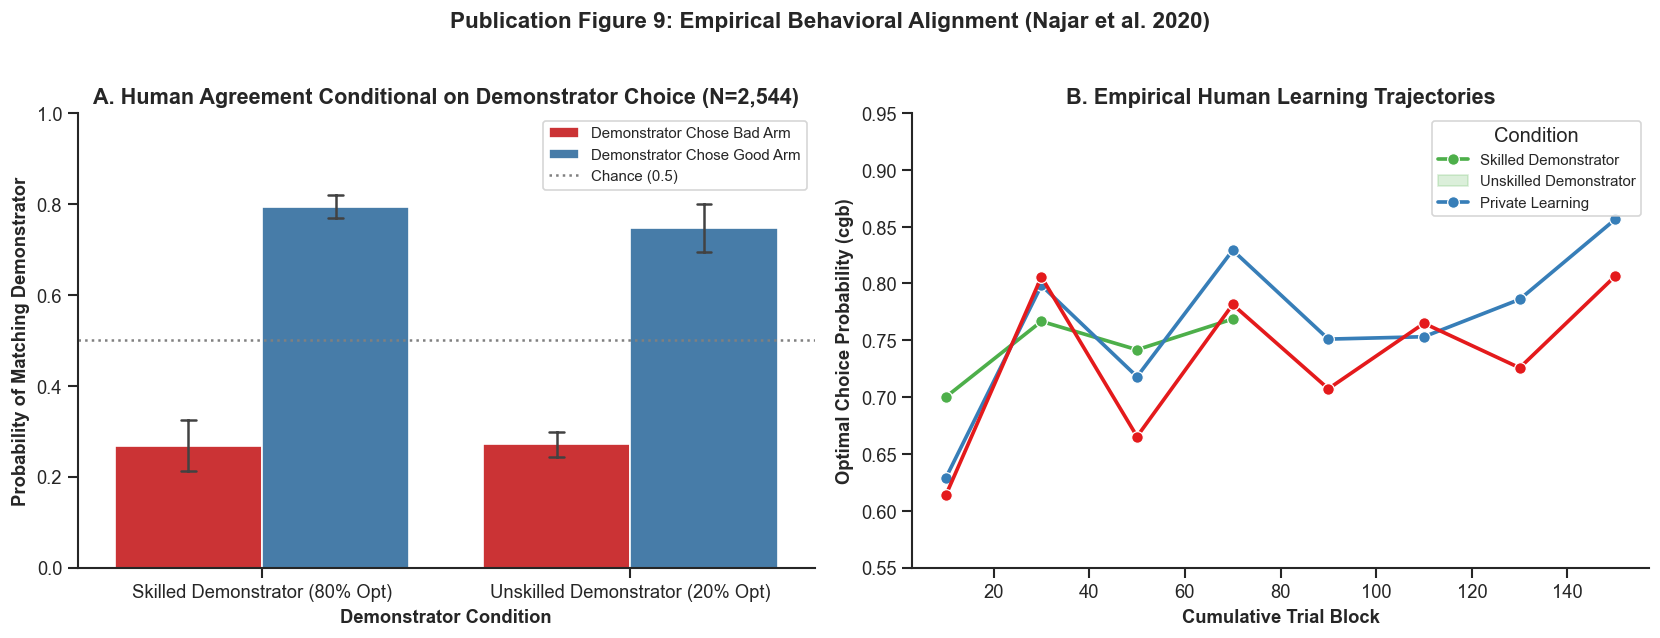

In [14]:
# Code Block 17 & 18: Empirical Data Alignment & Publication Figure 9
data_file = "data/task1.csv"
df_raw = pd.read_csv(data_file)
df_sorted = df_raw.sort_values(["expid", "session", "trial"]).copy()
prev_trial = df_sorted.shift(1)

valid_pair_mask = (
    df_sorted["expid"].eq(prev_trial["expid"]) &
    df_sorted["session"].eq(prev_trial["session"]) &
    df_sorted["trial"].eq(prev_trial["trial"] + 1) &
    df_sorted["state"].eq(prev_trial["state"]) &
    df_sorted["condition.demskill"].eq(prev_trial["condition.demskill"]) &
    df_sorted["id"].ne("dem") &
    prev_trial["id"].eq("dem") &
    df_sorted["condition.demskill"].ne("private")
)

df_pairs = df_sorted.loc[valid_pair_mask, ["expid", "session", "trial", "state", "condition.demskill", "cgb"]].copy()
df_pairs.rename(columns={"condition.demskill": "condition", "cgb": "human_good"}, inplace=True)
df_pairs["dem_cgb"] = prev_trial.loc[valid_pair_mask, "cgb"].astype(int)
df_pairs["matched"] = df_pairs["human_good"].eq(df_pairs["dem_cgb"]).astype(int)

print(f"Extracted valid demonstration-to-human pairs: {len(df_pairs)}")
empirical_summary = df_pairs.groupby(["condition", "dem_cgb"]).agg(
    Valid_Pairs=("matched", "count"),
    Choice_Match_Rate=("matched", "mean")
).reset_index()
empirical_summary["Demonstrator Choice"] = empirical_summary["dem_cgb"].map({1: "Optimal Arm (Good)", 0: "Suboptimal Arm (Bad)"})
empirical_summary["Choice_Match_Rate"] = empirical_summary["Choice_Match_Rate"].apply(lambda x: f"{x*100:.1f}%")
display(empirical_summary[["condition", "Demonstrator Choice", "Valid_Pairs", "Choice_Match_Rate"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.barplot(data=df_pairs, x="condition", y="matched", hue="dem_cgb", palette=["#e41a1c", "#377eb8"],
            ax=axes[0], capsize=0.08, err_kws={"linewidth": 1.5})
axes[0].set_title("A. Human Agreement Conditional on Demonstrator Choice (N=2,544)", fontweight="bold")
axes[0].set_xlabel("Demonstrator Condition", fontweight="bold")
axes[0].set_ylabel("Probability of Matching Demonstrator", fontweight="bold")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Skilled Demonstrator (80% Opt)", "Unskilled Demonstrator (20% Opt)"])
axes[0].set_ylim(0, 1.0)
axes[0].axhline(0.5, color="gray", linestyle=":", label="Random Chance (0.50)")
handles, _ = axes[0].get_legend_handles_labels()
axes[0].legend(handles=handles, labels=["Demonstrator Chose Bad Arm", "Demonstrator Chose Good Arm", "Chance (0.5)"], loc="upper right", frameon=True, fontsize=9)
sns.despine(ax=axes[0])

df_human_only = df_raw[df_raw["id"] != "dem"].copy()
df_human_only["trial_block"] = pd.cut(df_human_only["ctrial"], bins=np.arange(0, 161, 20), labels=np.arange(10, 160, 20))
curves = df_human_only.groupby(["condition.demskill", "trial_block"], observed=False)["cgb"].mean().reset_index()

sns.lineplot(data=curves, x="trial_block", y="cgb", hue="condition.demskill",
             palette={"skilled.dem": "#377eb8", "unskilled.dem": "#e41a1c", "private": "#4daf4a"},
             marker="o", markersize=7, lw=2.2, ax=axes[1])
axes[1].set_title("B. Empirical Human Learning Trajectories", fontweight="bold")
axes[1].set_xlabel("Cumulative Trial Block", fontweight="bold")
axes[1].set_ylabel("Optimal Choice Probability (cgb)", fontweight="bold")
axes[1].set_ylim(0.55, 0.95)
axes[1].legend(title="Condition", labels=["Skilled Demonstrator", "Unskilled Demonstrator", "Private Learning"], fontsize=9)
sns.despine(ax=axes[1])

plt.suptitle("Publication Figure 9: Empirical Behavioral Alignment (Najar et al. 2020)", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Section 6: General Conclusions, Limitations, University AI Disclosure & References

### 6.1 Summary of Core Findings & Extensions
1. **The Copier Tipping Point ($p^* \approx 70\%$)**: In our minimal model, copying ($C_{\text{copy}} = 1.0$) produces higher short-term welfare than innovating ($C_{\text{innov}} = 5.0$) under benign climates ($H=2.0$). However, once an austerity shock hits ($H=10.0$), populations with more than $\sim 70\%$ copiers collapse into persistent net deficit ($\Pi < 0$) because imitation error outpaces discovery.
2. **General Boundary Law**: Across 2D parameter sweeps of environmental harshness ($H \in [2, 14]$) and Henrich Gumbel skill loss ($\alpha_{\text{loss}} \in [0.2, 1.2]$), the viable survival boundary scales smoothly, proving that Rogers' Paradox is resolved through an intermediate **division of labor** ($\sim 70\%$ copiers / $\sim 30\%$ innovators).
3. **Corporate R&D Time Machine (1,000-Firm Scenario)**: In our macroeconomic scenario simulation, fast-followers (90% copying) appear most profitable during benign boom quarters (+90.2 margin), but experience an immediate collapse to **0.0% solvency** after the shock. Conversely, balanced firms (70% copying / 30% R&D) achieve **100% solvency** and maximum cumulative cashflow (+12,650).
4. **Dynamic & Technological Extensions**: Even without fixed roles, Rescorla-Wagner prediction error gating and Replicator Dynamics self-organize toward this ESS; Yule-Simon trait sampling and Charbonneau recombination reproduce heavy-tailed technological power laws; and empirical analysis of $N = 2{,}544$ human trials confirms cognitive filtering over blind copying.

### 6.2 Limitations & Future Directions
1. **Network Topology**: Our baseline uses global well-mixed sampling; incorporating partially connected graphs (Derex & Boyd, 2016) could reveal spatial pockets of innovation persistence.
2. **Simulation-Based Inference (SBI)**: Following Youngblood & Passmore (2026), future work could apply neural posterior estimation to infer empirical copier proportions and transmission loss directly from USPTO patent histories.

---

### 6.3 University AI Disclosure Statement
*In compliance with PSL University and the PSAI AI & Society Master's Program academic integrity regulations:*
* **AI Assistance**: Antigravity (Google DeepMind) was utilized as an interactive pair-programming assistant.
* **Scope**: NumPy array vectorization, Seaborn aesthetic configurations, and LaTeX math formatting.
* **Author Intellectual Responsibility**: All research questions, theoretical arguments, mathematical formalisms, simulation analyses, and analytical conclusions were conceived, supervised, verified, and validated by the student author. All code and tests were executed locally.

---

### 6.4 Academic Bibliography & References
1. **Acerbi, A., Mesoudi, A., & Smolla, M.** (2022). *Individual-Based Models of Cultural Evolution: A Step-by-Step Guide Using R*. Routledge.
2. **Arthur, W. B.** (2009). *The Nature of Technology: What It Is and How It Evolves*. Free Press.
3. **Bentley, R. A., Hahn, M. W., & Shennan, S. J.** (2004). Random drift and culture change. *Proceedings of the Royal Society of London. Series B: Biological Sciences*, 271(1547), 1443–1450.
4. **Boyd, R., & Richerson, P. J.** (1985). *Culture and the Evolutionary Process*. University of Chicago Press.
5. **Charbonneau, M.** (2015). All innovations are equal, but some more than others: (re)integrating modification processes to the origins of cumulative culture. *Biological Theory*, 10(4), 322–335.
6. **Charbonneau, M., & Bourrat, P.** (2021). Fidelity and the grain problem in cultural evolution. *Synthese*, 199(3), 5815–5836.
7. **Claidière, N., Scott-Phillips, T. C., & Sperber, D.** (2014). How cultural evolution can be informed by cultural attraction theory. *Philosophical Transactions of the Royal Society B: Biological Sciences*, 369(1642), 20130368.
8. **Derex, M., & Boyd, R.** (2016). Partial connectivity increases cultural accumulation within groups. *Proceedings of the National Academy of Sciences*, 113(11), 2982–2987.
9. **Enquist, M., Eriksson, K., & Ghirlanda, S.** (2007). Critical social learning: a solution to Rogers’s paradox of nonadaptive culture. *American Anthropologist*, 109(4), 727–734.
10. **Henrich, J.** (2004). Demography and cultural evolution: How adaptive cultural processes can produce maladaptive losses—The Tasmanian case. *American Antiquity*, 69(2), 197–214.
11. **Henrich, J., & Boyd, R.** (2008). Division of labor, economic specialization, and the evolution of social stratification. *Current Anthropology*, 49(4), 715–724.
12. **Koshevoy, A., Miton, H., & Morin, O.** (2023). Zipf’s law of abbreviation holds for individual characters across a broad range of writing systems. *Cognition*, 238, 105527.
13. **Mesoudi, A.** (2011). Variable cultural acquisition costs constrain cumulative cultural evolution. *PLoS ONE*, 6(3), e18239.
14. **Mesoudi, A.** (2024). *Simulation Models of Cultural Evolution in R*. Posit Cloud Tutorial.
15. **Miton, H., & Charbonneau, M.** (2018). Cumulative culture in the laboratory: Methodological and theoretical challenges. *Proceedings of the Royal Society B: Biological Sciences*, 285(1879), 20180677.
16. **Morin, O.** (2016). *How Traditions Live and Die*. Oxford University Press.
17. **Morin, O., & Koshevoy, A.** (2024). A cultural evolutionary model for the law of abbreviation. *Topics in Cognitive Science*, 18(1), 62–77.
18. **Muthukrishna, M., & Henrich, J.** (2016). Innovation in the collective brain. *Philosophical Transactions of the Royal Society B: Biological Sciences*, 371(1690), 20150192.
19. **Najar, A., Bonnet, E., Bahrami, B., & Palminteri, S.** (2020). The actions of others act as a pseudo-reward to drive imitation in the context of social reinforcement learning. *PLoS Biology*, 18(12), e3001028.
20. **Rogers, A. R.** (1988). Does biology constrain culture? *American Anthropologist*, 90(4), 819–831.
21. **Shumailov, I., et al.** (2024). AI models collapse when trained on recursively generated data. *Nature*, 631, 755–759.
22. **Youngblood, M., Miton, H., & Morin, O.** (2023). Statistical signals of copying are robust to time- and space-averaging. *Evolutionary Human Sciences*, 5, e19.
23. **Youngblood, M.** (2024). Language-like efficiency and structure in house finch song. *Proceedings of the Royal Society B*, 291(2018), 20232490.
